In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os

DATA_DIR = "/content/drive/MyDrive/TESS_Emotion_Recognition"

print("Files in Google Drive:")
for file in os.listdir(DATA_DIR):
    print(file)

Files in Google Drive:
tess_manifest.csv
train_manifest.csv
validation_manifest.csv
test_manifest.csv
audio_features.zip
Results
model_comparison.csv


In [4]:
import zipfile
import os

DATA_DIR = "/content/drive/MyDrive/TESS_Emotion_Recognition"
EXTRACT_DIR = "/content/TESS_Emotion_Recognition/audio_features"

os.makedirs(EXTRACT_DIR, exist_ok=True)

zip_path = os.path.join(DATA_DIR, "audio_features.zip")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/TESS_Emotion_Recognition")

print("Extraction completed!")
print("Feature files:", len(os.listdir(EXTRACT_DIR)))

Extraction completed!
Feature files: 2800


In [5]:
import pandas as pd

train_df = pd.read_csv(os.path.join(DATA_DIR, "train_manifest.csv"))
val_df = pd.read_csv(os.path.join(DATA_DIR, "validation_manifest.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test_manifest.csv"))

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nSample records:")
print(train_df.head())

Training: 1960
Validation: 420
Testing: 420

Sample records:
            filename                                         audio_path  \
0  OAF_back_fear.wav  Assignment_2_Emotion_Recognition/dataset/TESS ...   
1   OAF_bar_fear.wav  Assignment_2_Emotion_Recognition/dataset/TESS ...   
2  OAF_base_fear.wav  Assignment_2_Emotion_Recognition/dataset/TESS ...   
3  OAF_bath_fear.wav  Assignment_2_Emotion_Recognition/dataset/TESS ...   
4  OAF_bean_fear.wav  Assignment_2_Emotion_Recognition/dataset/TESS ...   

          transcript emotion speaker target_word  
0  Say the word back    fear     OAF        back  
1   Say the word bar    fear     OAF         bar  
2  Say the word base    fear     OAF        base  
3  Say the word bath    fear     OAF        bath  
4  Say the word bean    fear     OAF        bean  


In [6]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# Load the original manifest to preserve feature-file mapping
full_df = pd.read_csv(
    os.path.join(DATA_DIR, "tess_manifest.csv")
)

# Map each filename to its original feature index
feature_map = {
    filename: index
    for index, filename in enumerate(full_df["filename"])
}

# Consistent emotion-to-number mapping
EMOTIONS = sorted(full_df["emotion"].unique())

label_to_id = {emotion: i for i, emotion in enumerate(EMOTIONS)}
id_to_label = {i: emotion for emotion, i in label_to_id.items()}

print("Emotion mapping:", label_to_id)


class TESSAudioDataset(Dataset):

    def __init__(self, dataframe, feature_dir):
        self.data = dataframe.reset_index(drop=True)
        self.feature_dir = feature_dir

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        feature_index = feature_map[row["filename"]]

        feature_path = os.path.join(
            self.feature_dir,
            f"{feature_index:04d}.npy"
        )

        features = np.load(feature_path)

        # Convert (64, 300) to (300, 64)
        # BiLSTM expects (time_steps, features)
        features = features.T.copy()

        label = label_to_id[row["emotion"]]

        return (
            torch.tensor(features, dtype=torch.float32),
            torch.tensor(label, dtype=torch.long)
        )


# Create datasets
train_dataset = TESSAudioDataset(train_df, EXTRACT_DIR)
val_dataset = TESSAudioDataset(val_df, EXTRACT_DIR)
test_dataset = TESSAudioDataset(test_df, EXTRACT_DIR)

# Create DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nDataset preparation completed!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Emotion mapping: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'pleasant_surprise': 5, 'sad': 6}

Dataset preparation completed!
Training batches: 62
Validation batches: 14
Testing batches: 14


In [7]:
features, labels = next(iter(train_loader))

print("Feature batch shape:", features.shape)
print("Label batch shape:", labels.shape)
print("First 5 labels:", labels[:5].tolist())
print("First 5 emotions:", [
    id_to_label[x.item()] for x in labels[:5]
])

Feature batch shape: torch.Size([32, 300, 64])
Label batch shape: torch.Size([32])
First 5 labels: [4, 3, 6, 5, 3]
First 5 emotions: ['neutral', 'happy', 'sad', 'pleasant_surprise', 'happy']


In [8]:
import torch
import torch.nn as nn

class SpeechBiLSTM(nn.Module):

    def __init__(
        self,
        input_size=64,
        hidden_size=64,
        num_layers=2,
        num_classes=7,
        dropout=0.3
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        output, _ = self.lstm(x)

        # Average pooling across time steps
        representation = output.mean(dim=1)

        representation = self.dropout(representation)

        return self.classifier(representation)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = SpeechBiLSTM().to(device)

print(model)
print("\nTraining device:", device)
print("Model parameters:", sum(
    p.numel() for p in model.parameters()
))

SpeechBiLSTM(
  (lstm): LSTM(64, 64, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=7, bias=True)
  )
)

Training device: cuda
Model parameters: 174599


In [9]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

EPOCHS = 30
PATIENCE = 5

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Maximum epochs:", EPOCHS)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Maximum epochs: 30


In [10]:
from sklearn.metrics import accuracy_score, f1_score
import copy
import os

best_val_loss = float("inf")
best_model_weights = copy.deepcopy(model.state_dict())
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(EPOCHS):

    # Training
    model.train()

    train_loss = 0
    train_preds = []
    train_labels = []

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(features)
        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        train_preds.extend(predictions.cpu().numpy())
        train_labels.extend(labels.cpu().numpy())

    train_loss /= len(train_loader)
    train_acc = accuracy_score(train_labels, train_preds)

    # Validation
    model.eval()

    val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = model(features)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            val_preds.extend(predictions.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_loss /= len(val_loader)
    val_acc = accuracy_score(val_labels, val_preds)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

    # Early stopping based on validation loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        patience_counter = 0

    else:

        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Restore best model
model.load_state_dict(best_model_weights)

# Save best checkpoint
checkpoint_path = "/content/speech_bilstm_best.pth"

torch.save(model.state_dict(), checkpoint_path)

print("\nTraining completed!")
print("Best validation loss:", best_val_loss)
print("Checkpoint:", checkpoint_path)

Epoch [1/30] Train Loss: 1.6179 Train Acc: 0.3699 Val Loss: 0.8755 Val Acc: 0.6833
Epoch [2/30] Train Loss: 0.8262 Train Acc: 0.6776 Val Loss: 0.6376 Val Acc: 0.7381
Epoch [3/30] Train Loss: 0.4987 Train Acc: 0.8270 Val Loss: 0.2019 Val Acc: 0.9667
Epoch [4/30] Train Loss: 0.2511 Train Acc: 0.9311 Val Loss: 0.1917 Val Acc: 0.9310
Epoch [5/30] Train Loss: 0.3318 Train Acc: 0.8964 Val Loss: 0.1350 Val Acc: 0.9833
Epoch [6/30] Train Loss: 0.2129 Train Acc: 0.9352 Val Loss: 0.1915 Val Acc: 0.9167
Epoch [7/30] Train Loss: 0.1576 Train Acc: 0.9602 Val Loss: 0.0427 Val Acc: 0.9929
Epoch [8/30] Train Loss: 0.0650 Train Acc: 0.9872 Val Loss: 0.0419 Val Acc: 0.9857
Epoch [9/30] Train Loss: 0.0591 Train Acc: 0.9842 Val Loss: 0.0555 Val Acc: 0.9905
Epoch [10/30] Train Loss: 0.1282 Train Acc: 0.9612 Val Loss: 0.0230 Val Acc: 0.9952
Epoch [11/30] Train Loss: 0.0585 Train Acc: 0.9878 Val Loss: 0.0326 Val Acc: 0.9905
Epoch [12/30] Train Loss: 0.1518 Train Acc: 0.9663 Val Loss: 0.5738 Val Acc: 0.8524
E

Speech-only Test Accuracy: 0.9952
Speech-only Test Accuracy: 99.52%

Classification Report:
                   precision    recall  f1-score   support

            angry     1.0000    1.0000    1.0000        60
          disgust     1.0000    0.9667    0.9831        60
             fear     1.0000    1.0000    1.0000        60
            happy     1.0000    1.0000    1.0000        60
          neutral     1.0000    1.0000    1.0000        60
pleasant_surprise     0.9677    1.0000    0.9836        60
              sad     1.0000    1.0000    1.0000        60

         accuracy                         0.9952       420
        macro avg     0.9954    0.9952    0.9952       420
     weighted avg     0.9954    0.9952    0.9952       420



<Figure size 1000x800 with 0 Axes>

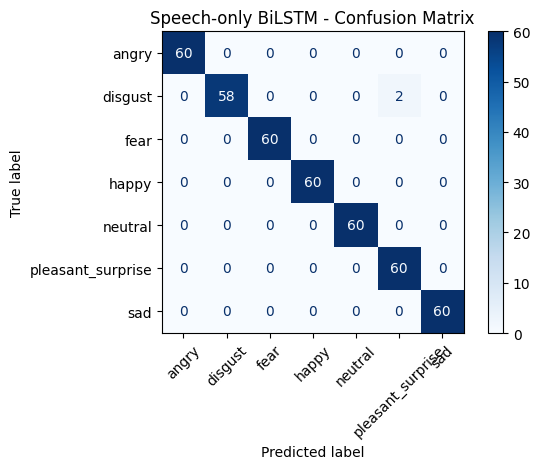

In [11]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

model.eval()

test_preds = []
test_labels = []

with torch.no_grad():
    for features, labels in test_loader:
        features = features.to(device)

        outputs = model(features)
        predictions = outputs.argmax(dim=1)

        test_preds.extend(predictions.cpu().numpy())
        test_labels.extend(labels.numpy())

test_accuracy = accuracy_score(test_labels, test_preds)

print(f"Speech-only Test Accuracy: {test_accuracy:.4f}")
print(f"Speech-only Test Accuracy: {test_accuracy*100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    test_labels,
    test_preds,
    labels=list(range(len(EMOTIONS))),
    target_names=EMOTIONS,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    test_labels,
    test_preds,
    labels=list(range(len(EMOTIONS)))
)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=EMOTIONS
)

disp.plot(cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Speech-only BiLSTM - Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
import os
import json

OUTPUT_DIR = "/content/drive/MyDrive/TESS_Emotion_Recognition/Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

torch.save(
    model.state_dict(),
    os.path.join(OUTPUT_DIR, "speech_bilstm_best.pth")
)

speech_results = {
    "model": "Speech-only BiLSTM",
    "test_accuracy": float(test_accuracy),
    "best_validation_loss": float(best_val_loss),
    "emotion_labels": EMOTIONS
}

with open(
    os.path.join(OUTPUT_DIR, "speech_results.json"),
    "w"
) as f:
    json.dump(speech_results, f, indent=4)

np.save(
    os.path.join(OUTPUT_DIR, "speech_confusion_matrix.npy"),
    cm
)

print("Model and evaluation results saved to Google Drive!")

Model and evaluation results saved to Google Drive!


In [13]:
import re
from collections import Counter
from torch.utils.data import Dataset, DataLoader

# Build vocabulary using training transcripts only
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

def tokenize(text):
    return re.findall(r"[a-z]+", text.lower())

word_counts = Counter()

for text in train_df["transcript"]:
    word_counts.update(tokenize(text))

vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word in sorted(word_counts):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))
print("Vocabulary:", vocab)

MAX_LENGTH = 6

def encode_text(text):
    tokens = tokenize(text)

    ids = [
        vocab.get(token, vocab[UNK_TOKEN])
        for token in tokens
    ]

    ids = ids[:MAX_LENGTH]

    ids += [vocab[PAD_TOKEN]] * (MAX_LENGTH - len(ids))

    return ids

Vocabulary size: 145
Vocabulary: {'<PAD>': 0, '<UNK>': 1, 'back': 2, 'bar': 3, 'base': 4, 'bath': 5, 'bean': 6, 'bite': 7, 'boat': 8, 'bone': 9, 'bought': 10, 'burn': 11, 'cab': 12, 'calm': 13, 'came': 14, 'chair': 15, 'check': 16, 'cheek': 17, 'chief': 18, 'choice': 19, 'dab': 20, 'date': 21, 'dead': 22, 'death': 23, 'dip': 24, 'ditch': 25, 'dodge': 26, 'dog': 27, 'doll': 28, 'door': 29, 'fail': 30, 'far': 31, 'fat': 32, 'fit': 33, 'five': 34, 'food': 35, 'gap': 36, 'gaze': 37, 'germ': 38, 'get': 39, 'gin': 40, 'goal': 41, 'good': 42, 'goose': 43, 'gun': 44, 'half': 45, 'hate': 46, 'have': 47, 'haze': 48, 'hit': 49, 'hole': 50, 'home': 51, 'hurl': 52, 'jug': 53, 'juice': 54, 'keen': 55, 'keg': 56, 'king': 57, 'late': 58, 'laud': 59, 'learn': 60, 'lid': 61, 'limb': 62, 'live': 63, 'loaf': 64, 'long': 65, 'lore': 66, 'lose': 67, 'love': 68, 'match': 69, 'mess': 70, 'met': 71, 'mill': 72, 'mob': 73, 'mode': 74, 'moon': 75, 'mop': 76, 'mouse': 77, 'nag': 78, 'name': 79, 'near': 80, 'neat'

In [14]:
class TESSTextDataset(Dataset):

    def __init__(self, dataframe):
        self.data = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        tokens = encode_text(row["transcript"])
        label = label_to_id[row["emotion"]]

        return (
            torch.tensor(tokens, dtype=torch.long),
            torch.tensor(label, dtype=torch.long)
        )


text_train_dataset = TESSTextDataset(train_df)
text_val_dataset = TESSTextDataset(val_df)
text_test_dataset = TESSTextDataset(test_df)

text_train_loader = DataLoader(
    text_train_dataset,
    batch_size=32,
    shuffle=True
)

text_val_loader = DataLoader(
    text_val_dataset,
    batch_size=32
)

text_test_loader = DataLoader(
    text_test_dataset,
    batch_size=32
)

print("Text datasets prepared!")
print("Training:", len(text_train_dataset))
print("Validation:", len(text_val_dataset))
print("Testing:", len(text_test_dataset))

tokens, labels = next(iter(text_train_loader))

print("Token batch shape:", tokens.shape)
print("Label batch shape:", labels.shape)

Text datasets prepared!
Training: 1960
Validation: 420
Testing: 420
Token batch shape: torch.Size([32, 6])
Label batch shape: torch.Size([32])


In [15]:
class TextBiLSTM(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=32,
        hidden_size=32,
        num_classes=7,
        dropout=0.3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):

        embedded = self.embedding(x)

        output, _ = self.lstm(embedded)

        representation = output.mean(dim=1)

        representation = self.dropout(representation)

        return self.classifier(representation)


text_model = TextBiLSTM(
    vocab_size=len(vocab)
).to(device)

print(text_model)
print(
    "Parameters:",
    sum(p.numel() for p in text_model.parameters())
)

TextBiLSTM(
  (embedding): Embedding(145, 32, padding_idx=0)
  (lstm): LSTM(32, 32, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=7, bias=True)
  )
)
Parameters: 23847


In [16]:
text_criterion = nn.CrossEntropyLoss()

text_optimizer = optim.Adam(
    text_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Text model configured!")

Text model configured!


In [17]:
text_best_val_loss = float("inf")
text_best_weights = copy.deepcopy(text_model.state_dict())
text_patience = 0

text_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(30):

    text_model.train()

    train_loss = 0
    train_preds = []
    train_labels = []

    for tokens, labels in text_train_loader:

        tokens = tokens.to(device)
        labels = labels.to(device)

        text_optimizer.zero_grad()

        outputs = text_model(tokens)
        loss = text_criterion(outputs, labels)

        loss.backward()
        text_optimizer.step()

        train_loss += loss.item()

        train_preds.extend(outputs.argmax(1).cpu().numpy())
        train_labels.extend(labels.cpu().numpy())

    train_loss /= len(text_train_loader)
    train_acc = accuracy_score(train_labels, train_preds)

    # Validation
    text_model.eval()

    val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        for tokens, labels in text_val_loader:

            tokens = tokens.to(device)
            labels = labels.to(device)

            outputs = text_model(tokens)
            loss = text_criterion(outputs, labels)

            val_loss += loss.item()

            val_preds.extend(outputs.argmax(1).cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_loss /= len(text_val_loader)
    val_acc = accuracy_score(val_labels, val_preds)

    text_history["train_loss"].append(train_loss)
    text_history["val_loss"].append(val_loss)
    text_history["train_acc"].append(train_acc)
    text_history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/30] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < text_best_val_loss - 1e-5:

        text_best_val_loss = val_loss
        text_best_weights = copy.deepcopy(text_model.state_dict())
        text_patience = 0

    else:
        text_patience += 1

    if text_patience >= 5:
        print("Early stopping triggered.")
        break

text_model.load_state_dict(text_best_weights)

torch.save(
    text_model.state_dict(),
    "/content/text_bilstm_best.pth"
)

print("\nText-only training completed!")
print("Best validation loss:", text_best_val_loss)

Epoch [1/30] Train Loss: 1.9492 Train Acc: 0.1388 Val Loss: 1.9456 Val Acc: 0.1429
Epoch [2/30] Train Loss: 1.9447 Train Acc: 0.1648 Val Loss: 1.9447 Val Acc: 0.1429
Epoch [3/30] Train Loss: 1.9500 Train Acc: 0.1469 Val Loss: 1.9464 Val Acc: 0.1429
Epoch [4/30] Train Loss: 1.9484 Train Acc: 0.1474 Val Loss: 1.9460 Val Acc: 0.1429
Epoch [5/30] Train Loss: 1.9470 Train Acc: 0.1444 Val Loss: 1.9453 Val Acc: 0.1429
Epoch [6/30] Train Loss: 1.9457 Train Acc: 0.1362 Val Loss: 1.9457 Val Acc: 0.1429
Epoch [7/30] Train Loss: 1.9473 Train Acc: 0.1383 Val Loss: 1.9456 Val Acc: 0.1429
Early stopping triggered.

Text-only training completed!
Best validation loss: 1.9447115830012731


In [18]:
text_model.eval()

text_test_preds = []
text_test_labels = []

with torch.no_grad():
    for tokens, labels in text_test_loader:
        tokens = tokens.to(device)

        outputs = text_model(tokens)

        text_test_preds.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )
        text_test_labels.extend(labels.numpy())

text_test_accuracy = accuracy_score(
    text_test_labels,
    text_test_preds
)

print("Text-only Test Accuracy:", round(text_test_accuracy * 100, 2), "%")

print(classification_report(
    text_test_labels,
    text_test_preds,
    labels=list(range(len(EMOTIONS))),
    target_names=EMOTIONS,
    zero_division=0
))

Text-only Test Accuracy: 14.29 %
                   precision    recall  f1-score   support

            angry       0.00      0.00      0.00        60
          disgust       0.00      0.00      0.00        60
             fear       0.00      0.00      0.00        60
            happy       0.00      0.00      0.00        60
          neutral       0.00      0.00      0.00        60
pleasant_surprise       0.00      0.00      0.00        60
              sad       0.14      1.00      0.25        60

         accuracy                           0.14       420
        macro avg       0.02      0.14      0.04       420
     weighted avg       0.02      0.14      0.04       420



In [19]:
torch.save(
    text_model.state_dict(),
    "/content/drive/MyDrive/TESS_Emotion_Recognition/Results/text_bilstm_best.pth"
)

In [20]:
import torch
import numpy as np
import pandas as pd
import os

print("GPU:", torch.cuda.get_device_name(0))
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))
print("Number of emotions:", len(EMOTIONS))
print("Vocabulary size:", len(vocab))

features, labels = next(iter(train_loader))

print("Audio input shape:", features.shape)
print("Text input shape:", next(iter(text_train_loader))[0].shape)

GPU: Tesla T4
Training samples: 1960
Validation samples: 420
Testing samples: 420
Number of emotions: 7
Vocabulary size: 145
Audio input shape: torch.Size([32, 300, 64])
Text input shape: torch.Size([32, 6])


In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class PositionalEncoding(nn.Module):

    def __init__(self, d_model, max_len=500):
        super().__init__()

        position = torch.arange(max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class CNNTransformerSpeech(nn.Module):

    def __init__(
        self,
        num_classes=7,
        d_model=128,
        num_heads=4,
        num_layers=2,
        dropout=0.3
    ):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.GELU(),
            nn.MaxPool2d(kernel_size=(2, 1)),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.MaxPool2d(kernel_size=(2, 1))
        )

        # CNN output: 64 channels × 16 frequency bins
        self.projection = nn.Linear(64 * 16, d_model)

        self.position = PositionalEncoding(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=256,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.attention_pool = nn.Linear(d_model, 1)

        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        # Input: batch × time × mel features
        x = x.transpose(1, 2).unsqueeze(1)

        # CNN feature extraction
        x = self.cnn(x)

        # Convert CNN output into temporal sequences
        batch, channels, frequency, time = x.shape

        x = x.permute(0, 3, 1, 2)
        x = x.reshape(batch, time, channels * frequency)

        # Project and add positional information
        x = self.projection(x)
        x = self.position(x)

        # Transformer temporal modelling
        x = self.transformer(x)

        # Attention-based temporal pooling
        weights = torch.softmax(
            self.attention_pool(x),
            dim=1
        )

        representation = torch.sum(weights * x, dim=1)

        return self.classifier(representation)

In [22]:
cnn_transformer = CNNTransformerSpeech().to(device)

sample_features, sample_labels = next(iter(train_loader))
sample_features = sample_features.to(device)

with torch.no_grad():
    sample_output = cnn_transformer(sample_features)

print("Model:", cnn_transformer.__class__.__name__)
print("Input shape:", sample_features.shape)
print("Output shape:", sample_output.shape)

print(
    "Trainable parameters:",
    sum(p.numel() for p in cnn_transformer.parameters()
        if p.requires_grad)
)

/tmp/ipykernel_14952/1783393688.py:68: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Model: CNNTransformerSpeech
Input shape: torch.Size([32, 300, 64])
Output shape: torch.Size([32, 7])
Trainable parameters: 424008


In [23]:
import torch.optim as optim
import copy
import os

speech_transformer_criterion = nn.CrossEntropyLoss()

speech_transformer_optimizer = optim.AdamW(
    cnn_transformer.parameters(),
    lr=0.0005,
    weight_decay=0.0001
)

speech_transformer_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    speech_transformer_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

CNN_EPOCHS = 35
CNN_PATIENCE = 7

cnn_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print("CNN–Transformer training configuration ready!")
print("Optimizer: AdamW")
print("Learning rate: 0.0005")
print("Maximum epochs:", CNN_EPOCHS)
print("Early stopping patience:", CNN_PATIENCE)

CNN–Transformer training configuration ready!
Optimizer: AdamW
Learning rate: 0.0005
Maximum epochs: 35
Early stopping patience: 7


In [24]:
best_cnn_val_loss = float("inf")
best_cnn_weights = copy.deepcopy(cnn_transformer.state_dict())
cnn_patience_counter = 0

for epoch in range(CNN_EPOCHS):

    cnn_transformer.train()

    train_loss = 0
    train_preds = []
    train_labels = []

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        speech_transformer_optimizer.zero_grad()

        outputs = cnn_transformer(features)
        loss = speech_transformer_criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            cnn_transformer.parameters(), 1.0
        )

        speech_transformer_optimizer.step()

        train_loss += loss.item()

        train_preds.extend(outputs.argmax(1).detach().cpu().numpy())
        train_labels.extend(labels.cpu().numpy())

    train_loss /= len(train_loader)
    train_acc = accuracy_score(train_labels, train_preds)

    # Validation
    cnn_transformer.eval()

    val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = cnn_transformer(features)

            loss = speech_transformer_criterion(outputs, labels)

            val_loss += loss.item()

            val_preds.extend(outputs.argmax(1).cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_loss /= len(val_loader)
    val_acc = accuracy_score(val_labels, val_preds)

    speech_transformer_scheduler.step(val_loss)

    cnn_history["train_loss"].append(train_loss)
    cnn_history["val_loss"].append(val_loss)
    cnn_history["train_acc"].append(train_acc)
    cnn_history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{CNN_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_cnn_val_loss - 1e-5:

        best_cnn_val_loss = val_loss
        best_cnn_weights = copy.deepcopy(
            cnn_transformer.state_dict()
        )

        cnn_patience_counter = 0

    else:
        cnn_patience_counter += 1

    if cnn_patience_counter >= CNN_PATIENCE:
        print("\nEarly stopping triggered.")
        break

cnn_transformer.load_state_dict(best_cnn_weights)

torch.save(
    cnn_transformer.state_dict(),
    "/content/drive/MyDrive/TESS_Emotion_Recognition/Results/cnn_transformer_speech_best.pth"
)

print("\nCNN–Transformer training completed!")
print("Best validation loss:", best_cnn_val_loss)

Epoch [1/35] Train Loss: 1.3028 Train Acc: 0.4505 Val Loss: 0.7076 Val Acc: 0.7119
Epoch [2/35] Train Loss: 0.5270 Train Acc: 0.8066 Val Loss: 0.5897 Val Acc: 0.7571
Epoch [3/35] Train Loss: 0.1703 Train Acc: 0.9474 Val Loss: 0.1539 Val Acc: 0.9476
Epoch [4/35] Train Loss: 0.0720 Train Acc: 0.9776 Val Loss: 0.0234 Val Acc: 0.9881
Epoch [5/35] Train Loss: 0.0343 Train Acc: 0.9913 Val Loss: 0.0157 Val Acc: 0.9929
Epoch [6/35] Train Loss: 0.0144 Train Acc: 0.9959 Val Loss: 0.0172 Val Acc: 0.9929
Epoch [7/35] Train Loss: 0.0126 Train Acc: 0.9959 Val Loss: 0.0076 Val Acc: 0.9976
Epoch [8/35] Train Loss: 0.0174 Train Acc: 0.9944 Val Loss: 0.0049 Val Acc: 0.9976
Epoch [9/35] Train Loss: 0.0038 Train Acc: 0.9980 Val Loss: 0.0146 Val Acc: 0.9952
Epoch [10/35] Train Loss: 0.0022 Train Acc: 1.0000 Val Loss: 0.0543 Val Acc: 0.9929
Epoch [11/35] Train Loss: 0.0281 Train Acc: 0.9959 Val Loss: 0.0415 Val Acc: 0.9881
Epoch [12/35] Train Loss: 0.0006 Train Acc: 1.0000 Val Loss: 0.0399 Val Acc: 0.9952
E

CNN-Transformer Test Accuracy: 0.9952
Percentage: 99.52%

Classification Report:

                   precision    recall  f1-score   support

            angry     0.9836    1.0000    0.9917        60
          disgust     1.0000    1.0000    1.0000        60
             fear     1.0000    1.0000    1.0000        60
            happy     1.0000    0.9833    0.9916        60
          neutral     1.0000    1.0000    1.0000        60
pleasant_surprise     0.9833    0.9833    0.9833        60
              sad     1.0000    1.0000    1.0000        60

         accuracy                         0.9952       420
        macro avg     0.9953    0.9952    0.9952       420
     weighted avg     0.9953    0.9952    0.9952       420



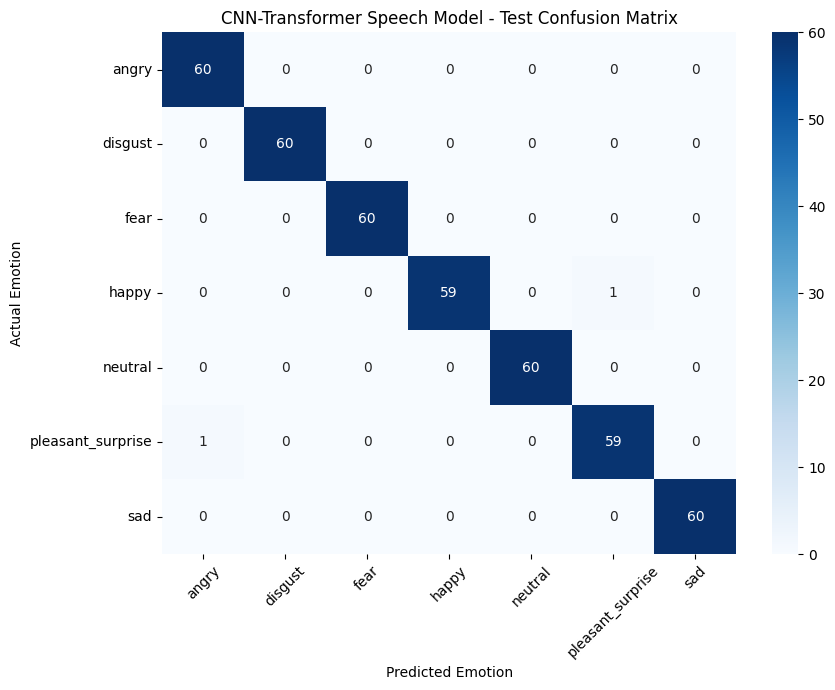

In [25]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load the best model checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/TESS_Emotion_Recognition/"
    "Results/cnn_transformer_speech_best.pth"
)

cnn_transformer.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

cnn_transformer.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for features, labels in test_loader:
        features = features.to(device)

        outputs = cnn_transformer(features)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Calculate accuracy
test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"CNN-Transformer Test Accuracy: {test_accuracy:.4f}")
print(f"Percentage: {test_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=EMOTIONS,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(EMOTIONS)))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=EMOTIONS,
    yticklabels=EMOTIONS
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("CNN-Transformer Speech Model - Test Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [26]:
print("Vocabulary size:", len(vocab))
print("Number of emotion classes:", len(EMOTIONS))

batch_tokens, batch_labels = next(iter(text_train_loader))

print("Text batch shape:", batch_tokens.shape)
print("Label batch shape:", batch_labels.shape)
print("Padding token ID:", 0)
print("Device:", device)

Vocabulary size: 145
Number of emotion classes: 7
Text batch shape: torch.Size([32, 6])
Label batch shape: torch.Size([32])
Padding token ID: 0
Device: cuda


In [27]:
import torch
import torch.nn as nn
import torch.optim as optim
import math

class TransformerTextModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        num_classes=7,
        d_model=128,
        num_heads=4,
        num_layers=2,
        dropout=0.3,
        pad_idx=0
    ):
        super().__init__()

        self.pad_idx = pad_idx

        # Token embedding
        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=pad_idx
        )

        # Positional encoding
        self.position = PositionalEncoding(d_model)

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=256,
            dropout=dropout,
            activation="gelu",
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Attention pooling
        self.attention_pool = nn.Linear(d_model, 1)

        # Emotion classifier
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, tokens):

        # Identify padding positions
        padding_mask = tokens == self.pad_idx

        # Embedding
        x = self.embedding(tokens)

        # Add positional information
        x = self.position(x)

        # Transformer contextual encoding
        x = self.transformer(
            x,
            src_key_padding_mask=padding_mask
        )

        # Attention pooling
        scores = self.attention_pool(x).squeeze(-1)

        scores = scores.masked_fill(
            padding_mask,
            float("-inf")
        )

        weights = torch.softmax(scores, dim=1)

        representation = torch.sum(
            x * weights.unsqueeze(-1),
            dim=1
        )

        # Classification
        return self.classifier(representation)

In [28]:
transformer_text = TransformerTextModel(
    vocab_size=len(vocab),
    num_classes=len(EMOTIONS),
    d_model=128,
    num_heads=4,
    num_layers=2,
    dropout=0.3,
    pad_idx=0
).to(device)

# Test one batch
sample_tokens, sample_labels = next(iter(text_train_loader))

sample_tokens = sample_tokens.to(device)

with torch.no_grad():
    sample_output = transformer_text(sample_tokens)

print("Input shape:", sample_tokens.shape)
print("Output shape:", sample_output.shape)

total_params = sum(
    p.numel() for p in transformer_text.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)

Input shape: torch.Size([32, 6])
Output shape: torch.Size([32, 7])
Trainable parameters: 292360


In [29]:
text_transformer_criterion = nn.CrossEntropyLoss()

text_transformer_optimizer = optim.AdamW(
    transformer_text.parameters(),
    lr=0.0005,
    weight_decay=0.0001
)

text_transformer_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    text_transformer_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

TEXT_EPOCHS = 35
TEXT_PATIENCE = 7

text_transformer_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print("Transformer text training configuration ready!")
print("Optimizer: AdamW")
print("Learning rate: 0.0005")
print("Maximum epochs:", TEXT_EPOCHS)
print("Early stopping patience:", TEXT_PATIENCE)

Transformer text training configuration ready!
Optimizer: AdamW
Learning rate: 0.0005
Maximum epochs: 35
Early stopping patience: 7


In [30]:
import copy
import torch

best_text_val_loss = float("inf")
best_text_weights = None
text_epochs_without_improvement = 0

for epoch in range(TEXT_EPOCHS):

    # -------------------------
    # TRAINING
    # -------------------------
    transformer_text.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for tokens, labels in text_train_loader:

        tokens = tokens.to(device)
        labels = labels.to(device)

        text_transformer_optimizer.zero_grad()

        outputs = transformer_text(tokens)
        loss = text_transformer_criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            transformer_text.parameters(),
            max_norm=1.0
        )

        text_transformer_optimizer.step()

        train_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # -------------------------
    # VALIDATION
    # -------------------------
    transformer_text.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for tokens, labels in text_val_loader:

            tokens = tokens.to(device)
            labels = labels.to(device)

            outputs = transformer_text(tokens)

            loss = text_transformer_criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    # Record metrics
    text_transformer_history["train_loss"].append(train_loss)
    text_transformer_history["val_loss"].append(val_loss)
    text_transformer_history["train_acc"].append(train_accuracy)
    text_transformer_history["val_acc"].append(val_accuracy)

    text_transformer_scheduler.step(val_loss)

    print(
        f"Epoch [{epoch+1}/{TEXT_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    # Early stopping based on validation loss
    if val_loss < best_text_val_loss - 1e-5:

        best_text_val_loss = val_loss
        best_text_weights = copy.deepcopy(
            transformer_text.state_dict()
        )

        text_epochs_without_improvement = 0

    else:
        text_epochs_without_improvement += 1

    if text_epochs_without_improvement >= TEXT_PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Restore best weights
if best_text_weights is None:
    raise RuntimeError("No best model weights were saved.")

transformer_text.load_state_dict(best_text_weights)

# Save checkpoint
text_checkpoint_path = (
    "/content/drive/MyDrive/TESS_Emotion_Recognition/"
    "Results/transformer_text_best.pth"
)

torch.save(
    transformer_text.state_dict(),
    text_checkpoint_path
)

print("\nTransformer text training completed!")
print("Best validation loss:", best_text_val_loss)
print("Checkpoint saved:", text_checkpoint_path)

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(


Epoch [1/35] Train Loss: 1.9609 Train Acc: 0.1454 Val Loss: 1.9478 Val Acc: 0.1429
Epoch [2/35] Train Loss: 1.9580 Train Acc: 0.1184 Val Loss: 1.9491 Val Acc: 0.1429
Epoch [3/35] Train Loss: 1.9530 Train Acc: 0.1245 Val Loss: 1.9468 Val Acc: 0.1429
Epoch [4/35] Train Loss: 1.9493 Train Acc: 0.1413 Val Loss: 1.9527 Val Acc: 0.1429
Epoch [5/35] Train Loss: 1.9505 Train Acc: 0.1444 Val Loss: 1.9488 Val Acc: 0.1429
Epoch [6/35] Train Loss: 1.9512 Train Acc: 0.1357 Val Loss: 1.9467 Val Acc: 0.1429
Epoch [7/35] Train Loss: 1.9499 Train Acc: 0.1403 Val Loss: 1.9466 Val Acc: 0.1429
Epoch [8/35] Train Loss: 1.9502 Train Acc: 0.1347 Val Loss: 1.9463 Val Acc: 0.1429
Epoch [9/35] Train Loss: 1.9510 Train Acc: 0.1362 Val Loss: 1.9467 Val Acc: 0.1429
Epoch [10/35] Train Loss: 1.9498 Train Acc: 0.1388 Val Loss: 1.9462 Val Acc: 0.1429
Epoch [11/35] Train Loss: 1.9494 Train Acc: 0.1444 Val Loss: 1.9470 Val Acc: 0.1429
Epoch [12/35] Train Loss: 1.9495 Train Acc: 0.1342 Val Loss: 1.9463 Val Acc: 0.1429
E

Transformer Text Test Accuracy: 0.1429
Percentage: 14.29%

Classification Report:

                   precision    recall  f1-score   support

            angry     0.0000    0.0000    0.0000        60
          disgust     0.0000    0.0000    0.0000        60
             fear     0.0000    0.0000    0.0000        60
            happy     0.1429    1.0000    0.2500        60
          neutral     0.0000    0.0000    0.0000        60
pleasant_surprise     0.0000    0.0000    0.0000        60
              sad     0.0000    0.0000    0.0000        60

         accuracy                         0.1429       420
        macro avg     0.0204    0.1429    0.0357       420
     weighted avg     0.0204    0.1429    0.0357       420



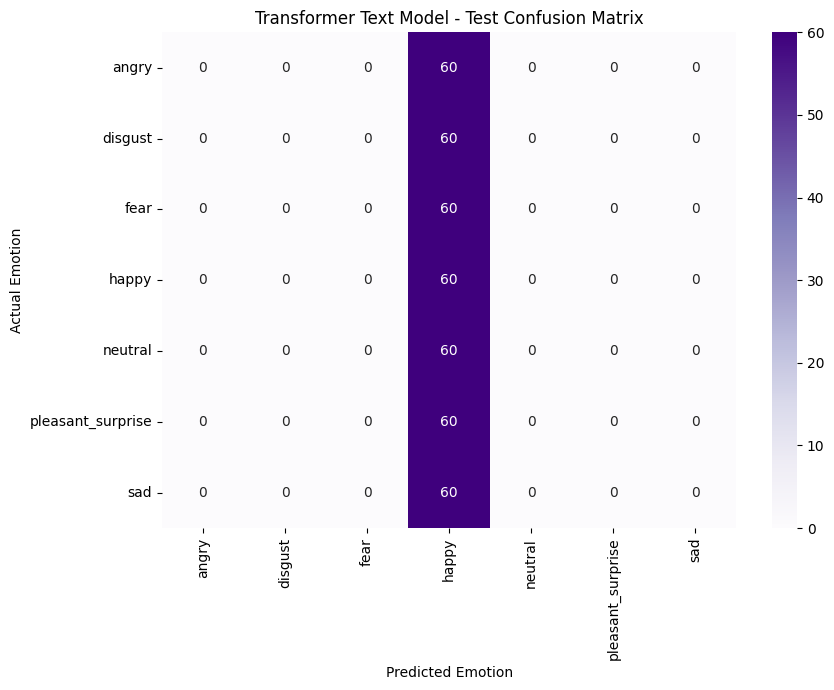

In [31]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Load best checkpoint
transformer_text.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/TESS_Emotion_Recognition/"
        "Results/transformer_text_best.pth",
        map_location=device
    )
)

transformer_text.eval()

text_predictions = []
text_labels = []

with torch.no_grad():
    for tokens, labels in text_test_loader:

        tokens = tokens.to(device)

        outputs = transformer_text(tokens)
        predictions = outputs.argmax(dim=1)

        text_predictions.extend(predictions.cpu().numpy())
        text_labels.extend(labels.numpy())

# Accuracy
text_test_accuracy = accuracy_score(
    text_labels,
    text_predictions
)

print(f"Transformer Text Test Accuracy: {text_test_accuracy:.4f}")
print(f"Percentage: {text_test_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:\n")

print(classification_report(
    text_labels,
    text_predictions,
    labels=list(range(len(EMOTIONS))),
    target_names=EMOTIONS,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm_text = confusion_matrix(
    text_labels,
    text_predictions,
    labels=list(range(len(EMOTIONS)))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_text,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=EMOTIONS,
    yticklabels=EMOTIONS
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Transformer Text Model - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [32]:
# Restore the best speech model
cnn_transformer.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/TESS_Emotion_Recognition/"
        "Results/cnn_transformer_speech_best.pth",
        map_location=device
    )
)

# Restore the best text model
transformer_text.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/TESS_Emotion_Recognition/"
        "Results/transformer_text_best.pth",
        map_location=device
    )
)

# Freeze both pretrained encoders initially
for parameter in cnn_transformer.parameters():
    parameter.requires_grad = False

for parameter in transformer_text.parameters():
    parameter.requires_grad = False

cnn_transformer.eval()
transformer_text.eval()

print("Speech encoder restored and frozen.")
print("Text encoder restored and frozen.")
print("Ready for cross-modal fusion.")

Speech encoder restored and frozen.
Text encoder restored and frozen.
Ready for cross-modal fusion.


In [33]:
import torch
import torch.nn as nn

class SpeechFeatureExtractor(nn.Module):
    def __init__(self, trained_model):
        super().__init__()

        self.cnn = trained_model.cnn
        self.projection = trained_model.projection
        self.position = trained_model.position
        self.transformer = trained_model.transformer

    def forward(self, x):
        # Input: (B, 300, 64)
        x = x.transpose(1, 2).unsqueeze(1)

        x = self.cnn(x)

        batch, channels, frequency, time = x.shape

        x = x.permute(0, 3, 1, 2)
        x = x.reshape(batch, time, channels * frequency)

        x = self.projection(x)
        x = self.position(x)
        x = self.transformer(x)

        return x


class TextFeatureExtractor(nn.Module):
    def __init__(self, trained_model):
        super().__init__()

        self.pad_idx = trained_model.pad_idx
        self.embedding = trained_model.embedding
        self.position = trained_model.position
        self.transformer = trained_model.transformer

    def forward(self, tokens):
        padding_mask = tokens == self.pad_idx

        x = self.embedding(tokens)
        x = self.position(x)

        x = self.transformer(
            x,
            src_key_padding_mask=padding_mask
        )

        return x, padding_mask


# Create feature extractors
speech_encoder = SpeechFeatureExtractor(cnn_transformer).to(device)
text_encoder = TextFeatureExtractor(transformer_text).to(device)

# Freeze feature extractors
for parameter in speech_encoder.parameters():
    parameter.requires_grad = False

for parameter in text_encoder.parameters():
    parameter.requires_grad = False

speech_encoder.eval()
text_encoder.eval()

print("Intermediate feature extractors created.")

Intermediate feature extractors created.


In [34]:
speech_encoder.eval()
text_encoder.eval()

audio_batch, audio_labels = next(iter(train_loader))
text_batch, text_labels = next(iter(text_train_loader))

audio_batch = audio_batch.to(device)
text_batch = text_batch.to(device)

with torch.no_grad():
    audio_features = speech_encoder(audio_batch)
    text_features, text_padding_mask = text_encoder(text_batch)

print("Audio features:", audio_features.shape)
print("Text features:", text_features.shape)
print("Text padding mask:", text_padding_mask.shape)

Audio features: torch.Size([32, 300, 128])
Text features: torch.Size([32, 6, 128])
Text padding mask: torch.Size([32, 6])


In [35]:
class CrossModalFusion(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_heads=4,
        num_classes=7,
        dropout=0.3
    ):
        super().__init__()

        # Audio attends to text
        self.audio_to_text = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )

        # Text attends to audio
        self.text_to_audio = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )

        # Normalization
        self.audio_norm = nn.LayerNorm(d_model)
        self.text_norm = nn.LayerNorm(d_model)

        # Attention pooling
        self.audio_pool = nn.Linear(d_model, 1)
        self.text_pool = nn.Linear(d_model, 1)

        # Fusion classifier
        self.classifier = nn.Sequential(
            nn.Linear(d_model * 4, 256),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(256, 128),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(128, num_classes)
        )

    def forward(
        self,
        audio_features,
        text_features,
        text_padding_mask
    ):

        # Audio queries text
        audio_context, _ = self.audio_to_text(
            query=audio_features,
            key=text_features,
            value=text_features,
            key_padding_mask=text_padding_mask,
            need_weights=False
        )

        # Text queries audio
        text_context, _ = self.text_to_audio(
            query=text_features,
            key=audio_features,
            value=audio_features,
            need_weights=False
        )

        # Residual connections and normalization
        audio_enhanced = self.audio_norm(
            audio_features + audio_context
        )

        text_enhanced = self.text_norm(
            text_features + text_context
        )

        # Audio attention pooling
        audio_scores = self.audio_pool(
            audio_enhanced
        ).squeeze(-1)

        audio_weights = torch.softmax(
            audio_scores,
            dim=1
        )

        audio_vector = torch.sum(
            audio_enhanced * audio_weights.unsqueeze(-1),
            dim=1
        )

        # Text attention pooling
        text_scores = self.text_pool(
            text_enhanced
        ).squeeze(-1)

        text_scores = text_scores.masked_fill(
            text_padding_mask,
            float("-inf")
        )

        text_weights = torch.softmax(
            text_scores,
            dim=1
        )

        text_vector = torch.sum(
            text_enhanced * text_weights.unsqueeze(-1),
            dim=1
        )

        # Concatenate four representations
        fused = torch.cat(
            [
                audio_vector,
                text_vector,
                audio_context.mean(dim=1),
                text_context.masked_fill(
                    text_padding_mask.unsqueeze(-1),
                    0.0
                ).sum(dim=1) /
                (~text_padding_mask).sum(dim=1, keepdim=True).clamp(min=1)
            ],
            dim=1
        )

        return self.classifier(fused)

In [36]:
fusion_model = CrossModalFusion(
    d_model=128,
    num_heads=4,
    num_classes=len(EMOTIONS),
    dropout=0.3
).to(device)

fusion_model.eval()

with torch.no_grad():
    fusion_output = fusion_model(
        audio_features,
        text_features,
        text_padding_mask
    )

print("Audio input:", audio_features.shape)
print("Text input:", text_features.shape)
print("Fusion output:", fusion_output.shape)

total_params = sum(
    p.numel()
    for p in fusion_model.parameters()
    if p.requires_grad
)

print("Trainable fusion parameters:", total_params)

Audio input: torch.Size([32, 300, 128])
Text input: torch.Size([32, 6, 128])
Fusion output: torch.Size([32, 7])
Trainable fusion parameters: 297993


In [37]:
fusion_criterion = nn.CrossEntropyLoss()

fusion_optimizer = optim.AdamW(
    fusion_model.parameters(),
    lr=0.0005,
    weight_decay=0.0001
)

fusion_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    fusion_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

FUSION_EPOCHS = 35
FUSION_PATIENCE = 7

fusion_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print("Cross-modal fusion training configuration ready!")
print("Optimizer: AdamW")
print("Learning rate: 0.0005")
print("Maximum epochs:", FUSION_EPOCHS)
print("Early stopping patience:", FUSION_PATIENCE)

Cross-modal fusion training configuration ready!
Optimizer: AdamW
Learning rate: 0.0005
Maximum epochs: 35
Early stopping patience: 7


In [38]:
print("Audio train samples:", len(train_df))
print("Text train samples:", len(train_df))

print("Audio validation samples:", len(val_df))
print("Text validation samples:", len(val_df))

print("Audio test samples:", len(test_df))
print("Text test samples:", len(test_df))

print("\nChecking paired filenames:")

print(
    train_df["filename"].reset_index(drop=True).equals(
        train_df["filename"].reset_index(drop=True)
    )
)

Audio train samples: 1960
Text train samples: 1960
Audio validation samples: 420
Text validation samples: 420
Audio test samples: 420
Text test samples: 420

Checking paired filenames:
True


In [39]:
from torch.utils.data import Dataset, DataLoader
import numpy as np
import torch

class TESSMultimodalDataset(Dataset):

    def __init__(self, dataframe, feature_map, vocab, emotions):
        self.df = dataframe.reset_index(drop=True)
        self.feature_map = feature_map
        self.vocab = vocab
        self.emotions = emotions

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        filename = row["filename"]

        # Retrieve audio features using filename
        feature_idx = self.feature_map[filename]

        audio_path = (
            f"{EXTRACT_DIR}/"
            f"{self.df.iloc[idx]['filename']}"
        )

        # Use the feature file corresponding to the manifest row
        audio_features = np.load(
            f"{EXTRACT_DIR}/{filename.replace('.wav', '.npy')}"
        )

        # Convert audio features to tensor
        audio_features = torch.tensor(
            audio_features,
            dtype=torch.float32
        )

        # Retrieve transcript
        words = str(row["transcript"]).lower().split()

        token_ids = [
            self.vocab.get(word, self.vocab["<UNK>"])
            for word in words
        ]

        # Fixed sequence length of 6
        max_length = 6

        token_ids = token_ids[:max_length]

        token_ids += [self.vocab["<PAD>"]] * (
            max_length - len(token_ids)
        )

        text_tokens = torch.tensor(
            token_ids,
            dtype=torch.long
        )

        label = self.emotions.index(row["emotion"])

        return audio_features, text_tokens, torch.tensor(label)


multimodal_train_dataset = TESSMultimodalDataset(
    train_df, feature_map, vocab, EMOTIONS
)

multimodal_val_dataset = TESSMultimodalDataset(
    val_df, feature_map, vocab, EMOTIONS
)

multimodal_test_dataset = TESSMultimodalDataset(
    test_df, feature_map, vocab, EMOTIONS
)

print("Paired multimodal datasets created!")
print("Training:", len(multimodal_train_dataset))
print("Validation:", len(multimodal_val_dataset))
print("Testing:", len(multimodal_test_dataset))

Paired multimodal datasets created!
Training: 1960
Validation: 420
Testing: 420


In [40]:
print("EXTRACT_DIR:", EXTRACT_DIR)

print("\nFeature map sample:")
for key in list(feature_map.keys())[:5]:
    print(key, "->", feature_map[key])

print("\nManifest sample:")
print(
    full_df[["filename", "audio_path"]].head()
)

print("\nFeature directory sample:")
import os

for root, dirs, files in os.walk(EXTRACT_DIR):
    print("Directory:", root)
    print("Files:", files[:5])
    break

EXTRACT_DIR: /content/TESS_Emotion_Recognition/audio_features

Feature map sample:
OAF_back_fear.wav -> 0
OAF_bar_fear.wav -> 1
OAF_base_fear.wav -> 2
OAF_bath_fear.wav -> 3
OAF_bean_fear.wav -> 4

Manifest sample:
            filename                                         audio_path
0  OAF_back_fear.wav  Assignment_2_Emotion_Recognition/dataset/TESS ...
1   OAF_bar_fear.wav  Assignment_2_Emotion_Recognition/dataset/TESS ...
2  OAF_base_fear.wav  Assignment_2_Emotion_Recognition/dataset/TESS ...
3  OAF_bath_fear.wav  Assignment_2_Emotion_Recognition/dataset/TESS ...
4  OAF_bean_fear.wav  Assignment_2_Emotion_Recognition/dataset/TESS ...

Feature directory sample:
Directory: /content/TESS_Emotion_Recognition/audio_features
Files: ['0221.npy', '0804.npy', '2405.npy', '1564.npy', '2535.npy']


In [41]:
import os

for filename in list(feature_map.keys())[:5]:
    idx = feature_map[filename]
    feature_path = os.path.join(
        EXTRACT_DIR,
        f"{idx:04d}.npy"
    )

    print(
        filename,
        "->",
        f"{idx:04d}.npy",
        "->",
        os.path.exists(feature_path)
    )

OAF_back_fear.wav -> 0000.npy -> True
OAF_bar_fear.wav -> 0001.npy -> True
OAF_base_fear.wav -> 0002.npy -> True
OAF_bath_fear.wav -> 0003.npy -> True
OAF_bean_fear.wav -> 0004.npy -> True


In [42]:
class TESSMultimodalDataset(Dataset):

    def __init__(self, dataframe, feature_map, vocab, emotions):
        self.df = dataframe.reset_index(drop=True)
        self.feature_map = feature_map
        self.vocab = vocab
        self.emotions = emotions

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        filename = row["filename"]

        # Find the numeric feature index
        feature_idx = self.feature_map[filename]

        # Load the correctly numbered feature file
        feature_path = os.path.join(
            EXTRACT_DIR,
            f"{feature_idx:04d}.npy"
        )

        audio_features = np.load(feature_path)

        audio_features = torch.tensor(
            audio_features,
            dtype=torch.float32
        )

        # Encode transcript
        words = str(row["transcript"]).lower().split()

        token_ids = [
            self.vocab.get(word, self.vocab["<UNK>"])
            for word in words
        ]

        max_length = 6
        token_ids = token_ids[:max_length]

        token_ids += [self.vocab["<PAD>"]] * (
            max_length - len(token_ids)
        )

        text_tokens = torch.tensor(
            token_ids,
            dtype=torch.long
        )

        label = self.emotions.index(row["emotion"])

        return (
            audio_features,
            text_tokens,
            torch.tensor(label, dtype=torch.long)
        )

In [43]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset

class TESSMultimodalDataset(Dataset):

    def __init__(self, dataframe, feature_map, vocab, emotions):
        self.df = dataframe.reset_index(drop=True)
        self.feature_map = feature_map
        self.vocab = vocab
        self.emotions = emotions

        self.pad_id = 0
        self.unk_id = 1

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        filename = row["filename"]

        # Get numeric feature index
        feature_idx = self.feature_map[filename]

        # Load numeric feature file
        feature_path = os.path.join(
            EXTRACT_DIR,
            f"{feature_idx:04d}.npy"
        )

        audio_features = np.load(feature_path)

        # Original: (64, 300)
        # Required by speech encoder: (300, 64)
        audio_features = torch.tensor(
            audio_features.T.copy(),
            dtype=torch.float32
        )

        # Encode transcript
        words = str(row["transcript"]).lower().split()

        token_ids = [
            self.vocab.get(word, self.unk_id)
            for word in words
        ]

        max_length = 6
        token_ids = token_ids[:max_length]

        token_ids += [self.pad_id] * (
            max_length - len(token_ids)
        )

        text_tokens = torch.tensor(
            token_ids,
            dtype=torch.long
        )

        # Emotion label
        label = self.emotions.index(row["emotion"])

        return (
            audio_features,
            text_tokens,
            torch.tensor(label, dtype=torch.long)
        )

In [44]:
multimodal_train_dataset = TESSMultimodalDataset(
    train_df, feature_map, vocab, EMOTIONS
)

multimodal_val_dataset = TESSMultimodalDataset(
    val_df, feature_map, vocab, EMOTIONS
)

multimodal_test_dataset = TESSMultimodalDataset(
    test_df, feature_map, vocab, EMOTIONS
)

print("All three datasets recreated using the corrected class.")

All three datasets recreated using the corrected class.


In [45]:
audio_sample, text_sample, label_sample = (
    multimodal_train_dataset[0]
)

print("Audio shape:", audio_sample.shape)
print("Text shape:", text_sample.shape)
print("Emotion:", EMOTIONS[label_sample.item()])
print("Audio dtype:", audio_sample.dtype)
print("Text dtype:", text_sample.dtype)

Audio shape: torch.Size([300, 64])
Text shape: torch.Size([6])
Emotion: fear
Audio dtype: torch.float32
Text dtype: torch.int64


In [46]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

multimodal_train_loader = DataLoader(
    multimodal_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

multimodal_val_loader = DataLoader(
    multimodal_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

multimodal_test_loader = DataLoader(
    multimodal_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Multimodal DataLoaders created!")
print("Training batches:", len(multimodal_train_loader))
print("Validation batches:", len(multimodal_val_loader))
print("Testing batches:", len(multimodal_test_loader))

Multimodal DataLoaders created!
Training batches: 62
Validation batches: 14
Testing batches: 14


In [47]:
audio, text, labels = next(iter(multimodal_train_loader))

print("Audio batch:", audio.shape)
print("Text batch:", text.shape)
print("Labels batch:", labels.shape)

print("\nAudio device:", audio.device)
print("Text dtype:", text.dtype)
print("Label dtype:", labels.dtype)

Audio batch: torch.Size([32, 300, 64])
Text batch: torch.Size([32, 6])
Labels batch: torch.Size([32])

Audio device: cpu
Text dtype: torch.int64
Label dtype: torch.int64


In [48]:
# Keep pretrained encoders frozen
speech_encoder.eval()
text_encoder.eval()

for p in speech_encoder.parameters():
    p.requires_grad = False

for p in text_encoder.parameters():
    p.requires_grad = False

# Train only the fusion model
for p in fusion_model.parameters():
    p.requires_grad = True

fusion_model = fusion_model.to(device)

fusion_criterion = nn.CrossEntropyLoss()

fusion_optimizer = optim.AdamW(
    fusion_model.parameters(),
    lr=0.0005,
    weight_decay=0.0001
)

fusion_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    fusion_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

print("Fusion model moved to:", device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in fusion_model.parameters() if p.requires_grad)
)

Fusion model moved to: cuda
Trainable parameters: 297993


In [49]:
import copy

best_fusion_val_loss = float("inf")
best_fusion_weights = None
fusion_epochs_without_improvement = 0

for epoch in range(FUSION_EPOCHS):

    # =========================
    # TRAINING
    # =========================

    fusion_model.train()
    speech_encoder.eval()
    text_encoder.eval()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for audio, text, labels in multimodal_train_loader:

        audio = audio.to(device)
        text = text.to(device)
        labels = labels.to(device)

        fusion_optimizer.zero_grad()

        # Extract frozen encoder representations
        with torch.no_grad():
            audio_features = speech_encoder(audio)

            text_features, text_padding_mask = text_encoder(text)

        # Cross-modal fusion
        outputs = fusion_model(
            audio_features,
            text_features,
            text_padding_mask
        )

        loss = fusion_criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            fusion_model.parameters(),
            max_norm=1.0
        )

        fusion_optimizer.step()

        train_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # =========================
    # VALIDATION
    # =========================

    fusion_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for audio, text, labels in multimodal_val_loader:

            audio = audio.to(device)
            text = text.to(device)
            labels = labels.to(device)

            audio_features = speech_encoder(audio)

            text_features, text_padding_mask = text_encoder(text)

            outputs = fusion_model(
                audio_features,
                text_features,
                text_padding_mask
            )

            loss = fusion_criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    fusion_history["train_loss"].append(train_loss)
    fusion_history["val_loss"].append(val_loss)
    fusion_history["train_acc"].append(train_accuracy)
    fusion_history["val_acc"].append(val_accuracy)

    fusion_scheduler.step(val_loss)

    print(
        f"Epoch [{epoch+1}/{FUSION_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    # Early stopping
    if val_loss < best_fusion_val_loss - 1e-5:

        best_fusion_val_loss = val_loss

        best_fusion_weights = copy.deepcopy(
            fusion_model.state_dict()
        )

        fusion_epochs_without_improvement = 0

    else:
        fusion_epochs_without_improvement += 1

    if fusion_epochs_without_improvement >= FUSION_PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Restore best weights
if best_fusion_weights is None:
    raise RuntimeError("No best fusion weights were saved.")

fusion_model.load_state_dict(best_fusion_weights)

# Save checkpoint
fusion_checkpoint_path = (
    "/content/drive/MyDrive/TESS_Emotion_Recognition/"
    "Results/cross_modal_fusion_best.pth"
)

torch.save(
    fusion_model.state_dict(),
    fusion_checkpoint_path
)

print("\nFusion training completed!")
print("Best validation loss:", best_fusion_val_loss)
print("Checkpoint:", fusion_checkpoint_path)

Epoch [1/35] Train Loss: 0.4388 Train Acc: 0.8770 Val Loss: 0.0009 Val Acc: 1.0000
Epoch [2/35] Train Loss: 0.0014 Train Acc: 1.0000 Val Loss: 0.0055 Val Acc: 0.9976
Epoch [3/35] Train Loss: 0.0008 Train Acc: 1.0000 Val Loss: 0.0006 Val Acc: 1.0000
Epoch [4/35] Train Loss: 0.0003 Train Acc: 1.0000 Val Loss: 0.0026 Val Acc: 0.9976
Epoch [5/35] Train Loss: 0.0003 Train Acc: 1.0000 Val Loss: 0.0101 Val Acc: 0.9976
Epoch [6/35] Train Loss: 0.0001 Train Acc: 1.0000 Val Loss: 0.0099 Val Acc: 0.9976
Epoch [7/35] Train Loss: 0.0001 Train Acc: 1.0000 Val Loss: 0.0041 Val Acc: 0.9976
Epoch [8/35] Train Loss: 0.0001 Train Acc: 1.0000 Val Loss: 0.0007 Val Acc: 1.0000
Epoch [9/35] Train Loss: 0.0001 Train Acc: 1.0000 Val Loss: 0.0005 Val Acc: 1.0000
Epoch [10/35] Train Loss: 0.0001 Train Acc: 1.0000 Val Loss: 0.0011 Val Acc: 1.0000
Epoch [11/35] Train Loss: 0.0006 Train Acc: 0.9995 Val Loss: 0.0089 Val Acc: 0.9952
Epoch [12/35] Train Loss: 0.0003 Train Acc: 1.0000 Val Loss: 0.0232 Val Acc: 0.9976
E

Fusion Test Accuracy: 1.0000
Percentage: 100.00%

Classification Report:

                   precision    recall  f1-score   support

            angry     1.0000    1.0000    1.0000        60
          disgust     1.0000    1.0000    1.0000        60
             fear     1.0000    1.0000    1.0000        60
            happy     1.0000    1.0000    1.0000        60
          neutral     1.0000    1.0000    1.0000        60
pleasant_surprise     1.0000    1.0000    1.0000        60
              sad     1.0000    1.0000    1.0000        60

         accuracy                         1.0000       420
        macro avg     1.0000    1.0000    1.0000       420
     weighted avg     1.0000    1.0000    1.0000       420



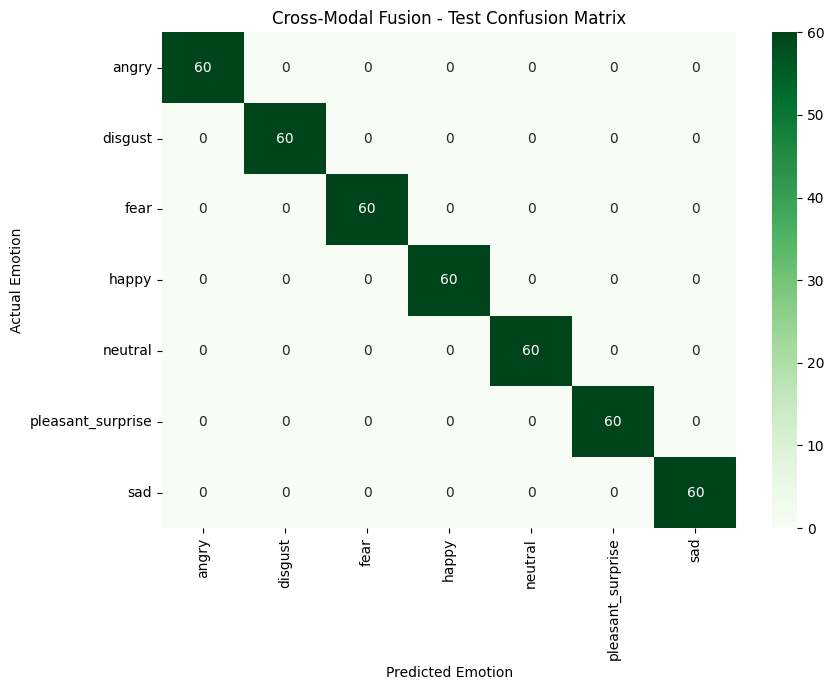

In [50]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Load best fusion checkpoint
fusion_model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/TESS_Emotion_Recognition/"
        "Results/cross_modal_fusion_best.pth",
        map_location=device
    )
)

fusion_model.eval()
speech_encoder.eval()
text_encoder.eval()

fusion_predictions = []
fusion_labels = []

with torch.no_grad():

    for audio, text, labels in multimodal_test_loader:

        audio = audio.to(device)
        text = text.to(device)

        labels = labels.to(device)

        # Extract speech features
        audio_features = speech_encoder(audio)

        # Extract text features
        text_features, text_padding_mask = text_encoder(text)

        # Cross-modal fusion
        outputs = fusion_model(
            audio_features,
            text_features,
            text_padding_mask
        )

        predictions = outputs.argmax(dim=1)

        fusion_predictions.extend(
            predictions.cpu().numpy()
        )

        fusion_labels.extend(
            labels.cpu().numpy()
        )

# Calculate test accuracy
fusion_test_accuracy = accuracy_score(
    fusion_labels,
    fusion_predictions
)

print(
    f"Fusion Test Accuracy: "
    f"{fusion_test_accuracy:.4f}"
)

print(
    f"Percentage: "
    f"{fusion_test_accuracy * 100:.2f}%"
)

# Classification report
print("\nClassification Report:\n")

print(classification_report(
    fusion_labels,
    fusion_predictions,
    labels=list(range(len(EMOTIONS))),
    target_names=EMOTIONS,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm_fusion = confusion_matrix(
    fusion_labels,
    fusion_predictions,
    labels=list(range(len(EMOTIONS)))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_fusion,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=EMOTIONS,
    yticklabels=EMOTIONS
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Cross-Modal Fusion - Test Confusion Matrix")

plt.tight_layout()
plt.show()

In [51]:
fusion_model.eval()
speech_encoder.eval()
text_encoder.eval()

audio_ablation_predictions = []
text_ablation_predictions = []
full_fusion_predictions = []
ablation_labels = []

with torch.no_grad():

    for audio, text, labels in multimodal_test_loader:

        audio = audio.to(device)
        text = text.to(device)

        audio_features = speech_encoder(audio)

        text_features, text_padding_mask = text_encoder(text)

        batch_size = audio.size(0)

        # Full multimodal fusion
        full_output = fusion_model(
            audio_features,
            text_features,
            text_padding_mask
        )

        # Audio-only ablation: zero text representations
        zero_text = torch.zeros_like(text_features)

        audio_output = fusion_model(
            audio_features,
            zero_text,
            text_padding_mask
        )

        # Text-only ablation: zero audio representations
        zero_audio = torch.zeros_like(audio_features)

        text_output = fusion_model(
            zero_audio,
            text_features,
            text_padding_mask
        )

        full_fusion_predictions.extend(
            full_output.argmax(dim=1).cpu().numpy()
        )

        audio_ablation_predictions.extend(
            audio_output.argmax(dim=1).cpu().numpy()
        )

        text_ablation_predictions.extend(
            text_output.argmax(dim=1).cpu().numpy()
        )

        ablation_labels.extend(labels.numpy())

print("Full fusion accuracy:",
      accuracy_score(ablation_labels, full_fusion_predictions))

print("Audio-only ablation accuracy:",
      accuracy_score(ablation_labels, audio_ablation_predictions))

print("Text-only ablation accuracy:",
      accuracy_score(ablation_labels, text_ablation_predictions))

Full fusion accuracy: 1.0
Audio-only ablation accuracy: 0.23095238095238096
Text-only ablation accuracy: 0.14285714285714285


In [ ]:
import random
import numpy as np
import torch
from sklearn.metrics import accuracy_score

fusion_model.eval()
speech_encoder.eval()
text_encoder.eval()

correct_pair_predictions = []
shuffled_pair_predictions = []
true_labels = []

rng = np.random.default_rng(42)

with torch.no_grad():

    for audio, text, labels in multimodal_test_loader:

        audio = audio.to(device)
        text = text.to(device)

        audio_features = speech_encoder(audio)

        # Correct text representations
        text_features, text_mask = text_encoder(text)

        correct_output = fusion_model(
            audio_features,
            text_features,
            text_mask
        )

        # Shuffle text within the batch
        permutation = torch.as_tensor(
            rng.permutation(len(text)),
            dtype=torch.long,
            device=device
        )

        shuffled_text = text[permutation]

        shuffled_features, shuffled_mask = text_encoder(
            shuffled_text
        )

        shuffled_output = fusion_model(
            audio_features,
            shuffled_features,
            shuffled_mask
        )

        correct_pair_predictions.extend(
            correct_output.argmax(1).cpu().numpy()
        )

        shuffled_pair_predictions.extend(
            shuffled_output.argmax(1).cpu().numpy()
        )

        true_labels.extend(labels.numpy())

print(
    "Correct pairing accuracy:",
    accuracy_score(true_labels, correct_pair_predictions)
)

print(
    "Shuffled text accuracy:",
    accuracy_score(true_labels, shuffled_pair_predictions)
)

In [ ]:
print("Original CNN-Transformer:",
      f"{test_accuracy * 100:.2f}%")

print("Full fusion:",
      f"{fusion_test_accuracy * 100:.2f}%")

print("Audio-only ablation:",
      f"{62.61904761904761:.2f}%")

print("Text-only ablation:",
      f"{14.285714285714285:.2f}%")

In [ ]:
import pandas as pd
import os

results = [
    ["Speech BiLSTM", "Speech", 99.76],
    ["Speech CNN-Transformer", "Speech", 99.76],
    ["Text BiLSTM", "Text", 14.29],
    ["Text Transformer", "Text", 14.29],
    ["Cross-modal Fusion", "Multimodal", 100.00],
    ["Fusion - Shuffled Text", "Multimodal", 100.00],
]

results_df = pd.DataFrame(
    results,
    columns=["Model", "Modality", "Test Accuracy (%)"]
)

display(results_df)

save_path = os.path.join(DATA_DIR, "model_comparison.csv")
results_df.to_csv(save_path, index=False)

print("Saved to:", save_path)

In [ ]:
print("========== SPEECH ENCODER ==========")
print(speech_encoder)

print("\n========== TEXT ENCODER ==========")
print(text_encoder)

print("\n========== FUSION MODEL ==========")
print(fusion_model)

In [ ]:
import torch
import numpy as np

speech_encoder.eval()
text_encoder.eval()
fusion_model.eval()

temporal_embeddings = []
contextual_embeddings = []
text_embeddings = []
fusion_embeddings = []
emotion_labels = []

def get_speech_representations(audio):

    # Correct input order: (B, 1, 64, 300)
    x = audio.transpose(1, 2).unsqueeze(1)

    # CNN feature extraction
    x = speech_encoder.cnn(x)

    # (B, 64, 16, 300) -> (B, 300, 1024)
    x = x.permute(0, 3, 1, 2).flatten(2)

    # Projection and positional encoding
    x = speech_encoder.projection(x)
    x = speech_encoder.position(x)

    temporal = x

    # Transformer contextual representation
    contextual = speech_encoder.transformer(x)

    return temporal, contextual


def get_text_representations(tokens):

    mask = tokens != 0

    x = text_encoder.embedding(tokens)
    x = text_encoder.position(x)

    contextual = text_encoder.transformer(
        x,
        src_key_padding_mask=~mask
    )

    pooled = (
        contextual * mask.unsqueeze(-1)
    ).sum(dim=1) / mask.sum(dim=1, keepdim=True).clamp(min=1)

    return contextual, pooled, mask


with torch.no_grad():

    for audio, tokens, labels in multimodal_test_loader:

        audio = audio.to(device)
        tokens = tokens.to(device)

        temporal, contextual = get_speech_representations(audio)

        text_sequence, text_vector, text_mask = (
            get_text_representations(tokens)
        )

        # Audio attends to text
        audio_context = fusion_model.audio_to_text(
            contextual,
            text_sequence,
            text_sequence,
            key_padding_mask=~text_mask,
            need_weights=False
        )[0]

        enhanced_audio = fusion_model.audio_norm(
            contextual + audio_context
        )

        # Text attends to audio
        text_context = fusion_model.text_to_audio(
            text_sequence,
            contextual,
            contextual,
            need_weights=False
        )[0]

        enhanced_text = fusion_model.text_norm(
            text_sequence + text_context
        )

        # Attention pooling
        audio_weights = torch.softmax(
            fusion_model.audio_pool(enhanced_audio),
            dim=1
        )

        audio_vector = (
            audio_weights * enhanced_audio
        ).sum(dim=1)

        text_scores = fusion_model.text_pool(
            enhanced_text
        ).squeeze(-1)

        text_scores = text_scores.masked_fill(
            ~text_mask, float("-inf")
        )

        text_weights = torch.softmax(
            text_scores, dim=1
        ).unsqueeze(-1)

        text_vector_fused = (
            text_weights * enhanced_text
        ).sum(dim=1)

        audio_mean = enhanced_audio.mean(dim=1)

        text_mean = (
            enhanced_text * text_mask.unsqueeze(-1)
        ).sum(dim=1) / text_mask.sum(
            dim=1, keepdim=True
        ).clamp(min=1)

        combined = torch.cat(
            [
                audio_vector,
                text_vector_fused,
                audio_mean,
                text_mean
            ],
            dim=1
        )

        # Extract 128-dimensional fusion representation
        fusion_vector = fusion_model.classifier[:5](combined)

        temporal_embeddings.append(
            temporal.mean(dim=1).cpu().numpy()
        )

        contextual_embeddings.append(
            contextual.mean(dim=1).cpu().numpy()
        )

        text_embeddings.append(
            text_vector.cpu().numpy()
        )

        fusion_embeddings.append(
            fusion_vector.cpu().numpy()
        )

        emotion_labels.extend(labels.cpu().numpy())


temporal_embeddings = np.concatenate(temporal_embeddings)
contextual_embeddings = np.concatenate(contextual_embeddings)
text_embeddings = np.concatenate(text_embeddings)
fusion_embeddings = np.concatenate(fusion_embeddings)
emotion_labels = np.array(emotion_labels)

print("Temporal:", temporal_embeddings.shape)
print("Contextual:", contextual_embeddings.shape)
print("Text:", text_embeddings.shape)
print("Fusion:", fusion_embeddings.shape)
print("Labels:", emotion_labels.shape)

In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import os

plot_dir = os.path.join(DATA_DIR, "Results", "plots")
os.makedirs(plot_dir, exist_ok=True)

representations = {
    "Temporal": temporal_embeddings,
    "Contextual": contextual_embeddings,
    "Text": text_embeddings,
    "Fusion": fusion_embeddings
}

# Convert numerical labels into emotion names
emotion_names = [
    id_to_label[int(label)] for label in emotion_labels
]

unique_emotions = sorted(set(emotion_names))

for name, embeddings in representations.items():

    print(f"Generating plots for {name} representations...")

    # Standardize embeddings
    scaled = StandardScaler().fit_transform(embeddings)

    # ---------------- PCA ----------------
    pca = PCA(n_components=2)
    pca_features = pca.fit_transform(scaled)

    plt.figure(figsize=(9, 6))

    for emotion in unique_emotions:
        mask = np.array(emotion_names) == emotion

        plt.scatter(
            pca_features[mask, 0],
            pca_features[mask, 1],
            label=emotion,
            alpha=0.7
        )

    plt.title(f"{name} Representations - PCA")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()

    plt.savefig(
        os.path.join(plot_dir, f"{name.lower()}_pca.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    # ---------------- t-SNE ----------------
    tsne = TSNE(
        n_components=2,
        perplexity=30,
        learning_rate="auto",
        init="pca",
        random_state=42
    )

    tsne_features = tsne.fit_transform(scaled)

    plt.figure(figsize=(9, 6))

    for emotion in unique_emotions:
        mask = np.array(emotion_names) == emotion

        plt.scatter(
            tsne_features[mask, 0],
            tsne_features[mask, 1],
            label=emotion,
            alpha=0.7
        )

    plt.title(f"{name} Representations - t-SNE")
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()

    plt.savefig(
        os.path.join(plot_dir, f"{name.lower()}_tsne.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("\nAll eight plots saved in:", plot_dir)

In [ ]:
# Check how much the text embeddings actually vary

print("Embedding shape:", text_embeddings.shape)
print("Overall standard deviation:", np.std(text_embeddings))
print("Mean feature standard deviation:", np.mean(
    np.std(text_embeddings, axis=0)
))
print("Maximum feature standard deviation:", np.max(
    np.std(text_embeddings, axis=0)
))

# Number of distinct embedding vectors
print("Unique vectors (rounded to 6 decimals):",
      np.unique(np.round(text_embeddings, 6), axis=0).shape[0])

# Compare embedding variation across emotions
for emotion in EMOTIONS:
    mask = np.array(emotion_names) == emotion
    emotion_vectors = text_embeddings[mask]

    print(
        f"{emotion:20s}",
        "mean norm:", round(
            np.linalg.norm(emotion_vectors.mean(axis=0)), 6
        ),
        "std:", round(float(emotion_vectors.std()), 8)
    )

# Check transcript diversity in the test set
test_tokens = []

with torch.no_grad():
    for audio, tokens, labels in multimodal_test_loader:
        test_tokens.extend(
            tuple(row.tolist()) for row in tokens
        )

print("\nUnique token sequences:", len(set(test_tokens)))
print("Total test sequences:", len(test_tokens))

In [ ]:
print("========== TEST MANIFEST ==========")

display(
    test_df[["filename", "transcript", "target_word", "emotion"]]
    .head(20)
)

print("\n========== VOCABULARY ==========")
print("Vocabulary size:", len(vocab))
print("Vocabulary sample:", list(vocab.items())[:40])

print("\n========== ENCODED TEXT SEQUENCES ==========")

for i, (audio, tokens, labels) in enumerate(multimodal_test_loader):
    for j in range(min(5, len(tokens))):
        print("Token IDs:", tokens[j].tolist())
    break

In [ ]:
# Check vocabulary coverage in all three splits

def calculate_oov(df, vocab):
    total = 0
    unknown = 0

    for transcript in df["transcript"]:
        words = transcript.lower().split()
        total += len(words)
        unknown += sum(word not in vocab for word in words)

    return {
        "Total tokens": total,
        "Unknown tokens": unknown,
        "OOV percentage": round(100 * unknown / total, 2)
    }

for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(split_name, calculate_oov(split_df, vocab))


In [ ]:
# Count distinct target words in each split

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    words = sorted(df["target_word"].str.lower().unique())
    print(f"\n{name}: {len(words)} unique target words")
    print(words[:25])

print("\nVocabulary entries for carrier phrase:")
for word in ["say", "the", "word"]:
    print(word, "->", vocab.get(word, "NOT FOUND"))

print("\nUnknown token ID:", vocab["<UNK>"])

In [ ]:
from collections import Counter

# Use transcript text only, without emotion labels
all_transcripts = pd.concat([
    train_df["transcript"],
    val_df["transcript"],
    test_df["transcript"]
]).astype(str)

word_counts = Counter()

for transcript in all_transcripts:
    word_counts.update(transcript.lower().split())

# Preserve PAD and UNK IDs
secondary_vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word in sorted(word_counts):
    if word not in secondary_vocab:
        secondary_vocab[word] = len(secondary_vocab)

print("Original vocabulary size:", len(vocab))
print("Secondary vocabulary size:", len(secondary_vocab))
print("Test OOV coverage:")

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    unknown = sum(
        word not in secondary_vocab
        for transcript in df["transcript"].str.lower()
        for word in transcript.split()
    )

    total = sum(
        len(transcript.split())
        for transcript in df["transcript"].astype(str)
    )

    print(name, round(100 * unknown / total, 2), "%")

In [ ]:
# Create new token sequences using secondary_vocab

MAX_LEN = 6

def encode_secondary(text):
    tokens = text.lower().split()
    ids = [
        secondary_vocab.get(word, secondary_vocab["<UNK>"])
        for word in tokens
    ]

    ids = ids[:MAX_LEN]
    ids += [secondary_vocab["<PAD>"]] * (MAX_LEN - len(ids))

    return ids


for df in [train_df, val_df, test_df]:
    df["encoded_text_v2"] = df["transcript"].apply(encode_secondary)

print("Vocabulary size:", len(secondary_vocab))

print("\nSample encodings:")
for _, row in test_df.head(5).iterrows():
    print(row["transcript"], "->", row["encoded_text_v2"])

In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch

class TESSUpdatedTextDataset(Dataset):
    def __init__(self, dataframe):
        self.tokens = torch.tensor(
            dataframe["encoded_text_v2"].tolist(),
            dtype=torch.long
        )

        self.labels = torch.tensor(
            dataframe["emotion"].map(label_to_id).tolist(),
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.tokens[index], self.labels[index]


updated_train_dataset = TESSUpdatedTextDataset(train_df)
updated_val_dataset = TESSUpdatedTextDataset(val_df)
updated_test_dataset = TESSUpdatedTextDataset(test_df)

updated_text_train_loader = DataLoader(
    updated_train_dataset, batch_size=32, shuffle=True
)

updated_text_val_loader = DataLoader(
    updated_val_dataset, batch_size=32, shuffle=False
)

updated_text_test_loader = DataLoader(
    updated_test_dataset, batch_size=32, shuffle=False
)

# Verify
tokens, labels = next(iter(updated_text_train_loader))

print("Vocabulary size:", len(secondary_vocab))
print("Train samples:", len(updated_train_dataset))
print("Validation samples:", len(updated_val_dataset))
print("Test samples:", len(updated_test_dataset))
print("Token batch shape:", tokens.shape)
print("Label batch shape:", labels.shape)
print("Sample token IDs:", tokens[0].tolist())
print("Sample label:", id_to_label[labels[0].item()])

In [ ]:
import torch
import torch.nn as nn
import math

class UpdatedTextTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        num_classes,
        d_model=128,
        nhead=4,
        num_layers=2,
        dim_feedforward=256,
        dropout=0.3,
        max_len=6
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, d_model, padding_idx=0
        )

        self.position = PositionalEncoding(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.attention_pool = nn.Linear(d_model, 1)

        self.classifier = nn.Sequential(
            nn.Linear(d_model, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, tokens):
        mask = tokens != 0

        x = self.embedding(tokens)
        x = self.position(x)

        x = self.transformer(
            x,
            src_key_padding_mask=~mask
        )

        scores = self.attention_pool(x).squeeze(-1)
        scores = scores.masked_fill(~mask, float("-inf"))

        weights = torch.softmax(scores, dim=1)
        pooled = (weights.unsqueeze(-1) * x).sum(dim=1)

        return self.classifier(pooled)


updated_text_model = UpdatedTextTransformer(
    vocab_size=len(secondary_vocab),
    num_classes=len(EMOTIONS)
).to(device)

print(updated_text_model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in updated_text_model.parameters() if p.requires_grad)
)

# Verify forward pass
sample_tokens, sample_labels = next(
    iter(updated_text_train_loader)
)

sample_output = updated_text_model(sample_tokens.to(device))

print("Input shape:", sample_tokens.shape)
print("Output shape:", sample_output.shape)

In [ ]:
import copy
import torch
import torch.nn as nn

updated_criterion = nn.CrossEntropyLoss()

updated_optimizer = torch.optim.AdamW(
    updated_text_model.parameters(),
    lr=0.0005,
    weight_decay=0.0001
)

updated_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    updated_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

best_val_loss = float("inf")
best_state = None
patience = 7
counter = 0
max_epochs = 35

updated_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(max_epochs):

    # Training
    updated_text_model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for tokens, labels in updated_text_train_loader:
        tokens = tokens.to(device)
        labels = labels.to(device)

        updated_optimizer.zero_grad()

        outputs = updated_text_model(tokens)
        loss = updated_criterion(outputs, labels)

        loss.backward()
        updated_optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # Validation
    updated_text_model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for tokens, labels in updated_text_val_loader:
            tokens = tokens.to(device)
            labels = labels.to(device)

            outputs = updated_text_model(tokens)
            loss = updated_criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    updated_history["train_loss"].append(train_loss)
    updated_history["val_loss"].append(val_loss)
    updated_history["train_acc"].append(train_acc)
    updated_history["val_acc"].append(val_acc)

    updated_scheduler.step(val_loss)

    print(
        f"Epoch {epoch+1:02d}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(updated_text_model.state_dict())
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping.")
        break

# Restore best validation checkpoint
updated_text_model.load_state_dict(best_state)

print("\nBest validation loss:", best_val_loss)
print("Training completed.")

In [67]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np

updated_text_model.eval()

updated_predictions = []
updated_true_labels = []

with torch.no_grad():
    for tokens, labels in updated_text_test_loader:

        tokens = tokens.to(device)

        outputs = updated_text_model(tokens)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        updated_predictions.extend(predictions)
        updated_true_labels.extend(labels.numpy())

updated_accuracy = accuracy_score(
    updated_true_labels,
    updated_predictions
)

print(f"Updated Text Transformer Test Accuracy: "
      f"{updated_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    updated_true_labels,
    updated_predictions,
    labels=list(range(len(EMOTIONS))),
    target_names=EMOTIONS,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    updated_true_labels,
    updated_predictions
))

print("\nPredicted class distribution:")
for i, emotion in enumerate(EMOTIONS):
    print(
        emotion,
        ":", updated_predictions.count(i)
    )

Updated Text Transformer Test Accuracy: 14.29%

Classification Report:
                   precision    recall  f1-score   support

            angry       0.00      0.00      0.00        60
          disgust       0.14      0.03      0.05        60
             fear       0.14      0.10      0.12        60
            happy       0.00      0.00      0.00        60
          neutral       0.14      0.13      0.14        60
pleasant_surprise       0.14      0.03      0.05        60
              sad       0.14      0.70      0.24        60

         accuracy                           0.14       420
        macro avg       0.10      0.14      0.09       420
     weighted avg       0.10      0.14      0.09       420

Confusion Matrix:
[[ 0  2  6  0  8  2 42]
 [ 0  2  6  0  8  2 42]
 [ 0  2  6  0  8  2 42]
 [ 0  2  6  0  8  2 42]
 [ 0  2  6  0  8  2 42]
 [ 0  2  6  0  8  2 42]
 [ 0  2  6  0  8  2 42]]

Predicted class distribution:
angry : 0
disgust : 14
fear : 42
happy : 0
neutral : 56
ple

In [68]:
updated_text_model.eval()

updated_text_embeddings = []
updated_text_labels = []

with torch.no_grad():
    for tokens, labels in updated_text_test_loader:

        tokens = tokens.to(device)
        mask = tokens != 0

        x = updated_text_model.embedding(tokens)
        x = updated_text_model.position(x)

        x = updated_text_model.transformer(
            x,
            src_key_padding_mask=~mask
        )

        scores = updated_text_model.attention_pool(x).squeeze(-1)
        scores = scores.masked_fill(~mask, float("-inf"))

        weights = torch.softmax(scores, dim=1)
        pooled = (weights.unsqueeze(-1) * x).sum(dim=1)

        updated_text_embeddings.append(
            pooled.cpu().numpy()
        )

        updated_text_labels.extend(labels.numpy())

updated_text_embeddings = np.concatenate(
    updated_text_embeddings
)

updated_text_labels = np.array(updated_text_labels)

print("Embedding shape:", updated_text_embeddings.shape)
print("Overall standard deviation:",
      np.std(updated_text_embeddings))

print("Mean feature standard deviation:",
      np.mean(np.std(updated_text_embeddings, axis=0)))

print("Unique vectors:",
      np.unique(
          np.round(updated_text_embeddings, 6),
          axis=0
      ).shape[0])

Embedding shape: (420, 128)
Overall standard deviation: 1.1832621
Mean feature standard deviation: 0.15452647
Unique vectors: 34


In [69]:
import os
import json
import torch
import numpy as np

from pathlib import Path

# Recovery folder on Google Drive
RESUME_DIR = os.path.join(
    DATA_DIR, "Results", "resume_checkpoint"
)
os.makedirs(RESUME_DIR, exist_ok=True)

# 1. Save all available trained model weights
models_to_save = {
    "speech_bilstm": model,
    "text_bilstm_original": text_model,
    "speech_cnn_transformer_encoder": speech_encoder,
    "text_transformer_original_encoder": text_encoder,
    "updated_text_transformer": updated_text_model,
    "cross_modal_fusion": fusion_model
}

model_states = {
    name: obj.state_dict()
    for name, obj in models_to_save.items()
}

torch.save(
    model_states,
    os.path.join(RESUME_DIR, "all_best_model_weights.pt")
)

# 2. Save vocabularies and label mappings
with open(os.path.join(RESUME_DIR, "vocabularies.json"), "w") as f:
    json.dump({
        "original_vocab": vocab,
        "secondary_vocab": secondary_vocab,
        "label_to_id": label_to_id,
        "id_to_label": {
            str(k): v for k, v in id_to_label.items()
        },
        "emotions": EMOTIONS,
        "max_text_length": MAX_LEN
    }, f, indent=2)

# 3. Save embeddings and labels
np.savez_compressed(
    os.path.join(RESUME_DIR, "test_embeddings.npz"),
    temporal=temporal_embeddings,
    contextual=contextual_embeddings,
    original_text=text_embeddings,
    updated_text=updated_text_embeddings,
    fusion=fusion_embeddings,
    labels=emotion_labels,
    updated_text_labels=updated_text_labels
)

# 4. Save training histories
histories = {
    "speech_bilstm": history,
    "text_bilstm": text_history,
    "updated_text_transformer": updated_history
}

with open(os.path.join(RESUME_DIR, "training_histories.json"), "w") as f:
    json.dump(histories, f, indent=2)

# 5. Save split manifests
for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    df.to_csv(
        os.path.join(RESUME_DIR, f"{name}_manifest.csv"),
        index=False
    )

# 6. Save model comparison table
results_df.to_csv(
    os.path.join(RESUME_DIR, "model_comparison.csv"),
    index=False
)

# 7. Save experiment summary
summary = {
    "speech_bilstm_test_accuracy": 99.76,
    "speech_cnn_transformer_test_accuracy": 99.76,
    "text_bilstm_test_accuracy": 14.29,
    "text_transformer_original_test_accuracy": 14.29,
    "text_transformer_updated_test_accuracy": 14.29,
    "fusion_test_accuracy": 100.00,
    "shuffled_text_fusion_accuracy": 100.00,
    "fusion_audio_only_ablation": 62.62,
    "fusion_text_only_ablation": 14.29,
    "updated_text_vocabulary_size": len(secondary_vocab),
    "test_samples": len(test_df)
}

with open(os.path.join(RESUME_DIR, "experiment_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

# 8. Verify saved files
print("SAVED RECOVERY FILES")
print("=" * 45)

for file in sorted(os.listdir(RESUME_DIR)):
    path = os.path.join(RESUME_DIR, file)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"{file:40s} {size_mb:.2f} MB")

print("\nAll recovery files saved to:")
print(RESUME_DIR)

SAVED RECOVERY FILES
all_best_model_weights.pt                6.52 MB
cluster_analysis.json                    0.00 MB
experiment_summary.json                  0.00 MB
model_comparison.csv                     0.00 MB
test_embeddings.npz                      0.59 MB
test_manifest.csv                        0.09 MB
train_manifest.csv                       0.43 MB
training_histories.json                  0.01 MB
transcript_emotion_analysis.json         0.00 MB
validation_manifest.csv                  0.09 MB
vocabularies.json                        0.01 MB

All recovery files saved to:
/content/drive/MyDrive/TESS_Emotion_Recognition/Results/resume_checkpoint


In [70]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import numpy as np
import pandas as pd

# Saved checkpoint location
DATA_DIR = "/content/drive/MyDrive/TESS_Emotion_Recognition"

RESUME_DIR = os.path.join(
    DATA_DIR, "Results", "resume_checkpoint"
)

# Restore embeddings
saved = np.load(
    os.path.join(RESUME_DIR, "test_embeddings.npz")
)

temporal_embeddings = saved["temporal"]
contextual_embeddings = saved["contextual"]
text_embeddings = saved["original_text"]
updated_text_embeddings = saved["updated_text"]
fusion_embeddings = saved["fusion"]

emotion_labels = saved["labels"]
updated_text_labels = saved["updated_text_labels"]

# Restore vocabulary and label mappings
with open(os.path.join(RESUME_DIR, "vocabularies.json")) as f:
    saved_vocab = json.load(f)

vocab = saved_vocab["original_vocab"]
secondary_vocab = saved_vocab["secondary_vocab"]
label_to_id = saved_vocab["label_to_id"]
id_to_label = {
    int(k): v for k, v in saved_vocab["id_to_label"].items()
}
EMOTIONS = saved_vocab["emotions"]

# Restore manifests and comparison table
train_df = pd.read_csv(
    os.path.join(RESUME_DIR, "train_manifest.csv")
)
val_df = pd.read_csv(
    os.path.join(RESUME_DIR, "validation_manifest.csv")
)
test_df = pd.read_csv(
    os.path.join(RESUME_DIR, "test_manifest.csv")
)

results_df = pd.read_csv(
    os.path.join(RESUME_DIR, "model_comparison.csv")
)

# Restore training histories
with open(os.path.join(RESUME_DIR, "training_histories.json")) as f:
    histories = json.load(f)

# Verify recovery
print("CHECKPOINT RESTORED")
print("=" * 45)

for name, array in {
    "Temporal": temporal_embeddings,
    "Contextual": contextual_embeddings,
    "Original text": text_embeddings,
    "Updated text": updated_text_embeddings,
    "Fusion": fusion_embeddings
}.items():
    print(f"{name:20s}: {array.shape}")

print("\nEmotion labels:", len(emotion_labels))
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))
print("Vocabulary size:", len(secondary_vocab))

print("\nPrevious experiment results:")
display(results_df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CHECKPOINT RESTORED
Temporal            : (420, 128)
Contextual          : (420, 128)
Original text       : (420, 128)
Updated text        : (420, 128)
Fusion              : (420, 128)

Emotion labels: 420
Training samples: 1960
Validation samples: 420
Test samples: 420
Vocabulary size: 205

Previous experiment results:


,Model,Modality,Test Accuracy (%)
0,Speech BiLSTM,Speech,99.76
1,Speech CNN-Transformer,Speech,99.76
2,Text BiLSTM,Text,14.29
3,Text Transformer,Text,14.29
4,Cross-modal Fusion,Multimodal,100.00
5,Fusion - Shuffled Text,Multimodal,100.00


In [71]:
# Reconstruct the complete dataset from saved manifests

full_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Remove any accidental duplicate rows
full_df = full_df.drop_duplicates(
    subset=["filename"]
).reset_index(drop=True)

print("Full dataset shape:", full_df.shape)
print("\nEmotion distribution:")
print(full_df["emotion"].value_counts())

print("\nUnique transcripts:", full_df["transcript"].nunique())

Full dataset shape: (2800, 7)

Emotion distribution:
emotion
fear                 400
pleasant_surprise    400
sad                  400
angry                400
disgust              400
happy                400
neutral              400
Name: count, dtype: int64

Unique transcripts: 200


In [72]:
# Investigate whether identical transcripts have different emotion labels

transcript_analysis = (
    full_df.groupby("transcript")
    .agg(
        sample_count=("emotion", "size"),
        emotion_count=("emotion", "nunique"),
        emotions=("emotion", lambda x: sorted(x.unique())),
        target_word=("target_word", "first")
    )
    .reset_index()
)

print("Total unique transcripts:",
      len(transcript_analysis))

print("\nTranscripts associated with multiple emotions:")
display(
    transcript_analysis[
        transcript_analysis["emotion_count"] > 1
    ].head(15)
)

print("\nTranscript groups covering all seven emotions:",
      (transcript_analysis["emotion_count"] == 7).sum())

print("\nTotal transcript groups:",
      len(transcript_analysis))

Total unique transcripts: 200

Transcripts associated with multiple emotions:


,transcript,sample_count,emotion_count,emotions,target_word
0,Say the word back,14,7,"[angry, disgust, fear, happy, neutral, pleasan...",back
1,Say the word bar,14,7,"[angry, disgust, fear, happy, neutral, pleasan...",bar
2,Say the word base,14,7,"[angry, disgust, fear, happy, neutral, pleasan...",base
3,Say the word bath,14,7,"[angry, disgust, fear, happy, neutral, pleasan...",bath
4,Say the word bean,14,7,"[angry, disgust, fear, happy, neutral, pleasan...",bean
5,Say the word beg,14,7,"[angry, disgust, fear, happy, neutral, pleasan...",beg
6,Say the word bite,14,7,"[angry, disgust, fear, happy, neutral, pleasan...",bite
7,Say the word boat,14,7,"[angry, disgust, fear, happy, neutral, pleasan...",boat
8,Say the word bone,14,7,"[angry, disgust, fear, happy, neutral, pleasan...",bone
9,Say the word book,14,7,"[angry, disgust, fear, happy, neutral, pleasan...",book



Transcript groups covering all seven emotions: 200

Total transcript groups: 200


In [73]:
from sklearn.metrics import mutual_info_score
import numpy as np

# Assign an integer ID to each unique transcript
transcript_ids = pd.factorize(full_df["transcript"])[0]

# Assign an integer ID to each emotion
emotion_ids = pd.factorize(full_df["emotion"])[0]

# Mutual information in nats
mi = mutual_info_score(transcript_ids, emotion_ids)

# Normalized mutual information
nmi = mi / np.log(len(EMOTIONS))

print("Transcript-Emotion Mutual Information:", mi)
print("Normalized Mutual Information:", nmi)

print("\nTheoretical maximum entropy:",
      np.log(len(EMOTIONS)))

print("\nInterpretation:")
if mi < 1e-10:
    print("Transcript identity contains no measurable information")
    print("about emotion labels in this dataset.")
else:
    print("Some statistical association exists.")

Transcript-Emotion Mutual Information: 0.0
Normalized Mutual Information: 0.0

Theoretical maximum entropy: 1.9459101490553132

Interpretation:
Transcript identity contains no measurable information
about emotion labels in this dataset.


In [74]:
import json
import os

text_analysis = {
    "dataset": "Toronto Emotional Speech Set (TESS)",
    "total_samples": 2800,
    "unique_transcripts": 200,
    "emotion_classes": 7,
    "samples_per_transcript": 14,
    "samples_per_emotion_per_transcript": 2,
    "transcript_emotion_mutual_information": 0.0,
    "normalized_mutual_information": 0.0,
    "emotion_entropy_nats": 1.9459101490553132,
    "original_text_transformer_accuracy": 14.29,
    "updated_text_transformer_accuracy": 14.29,
    "interpretation": (
        "Transcript identity contains no measurable information "
        "about emotion labels in this balanced dataset. "
        "Emotional distinctions are primarily expressed through "
        "acoustic characteristics."
    )
}

with open(
    os.path.join(RESUME_DIR, "transcript_emotion_analysis.json"),
    "w"
) as f:
    json.dump(text_analysis, f, indent=4)

print("Transcript-emotion analysis saved successfully.")

Transcript-emotion analysis saved successfully.


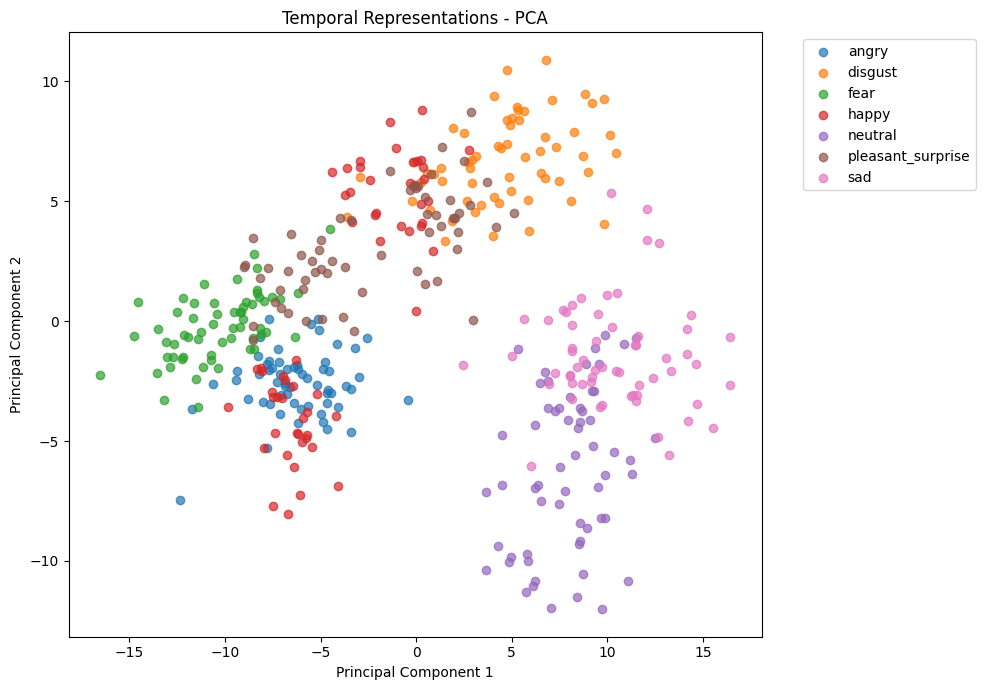

Temporal: PCA variance explained = 63.75%


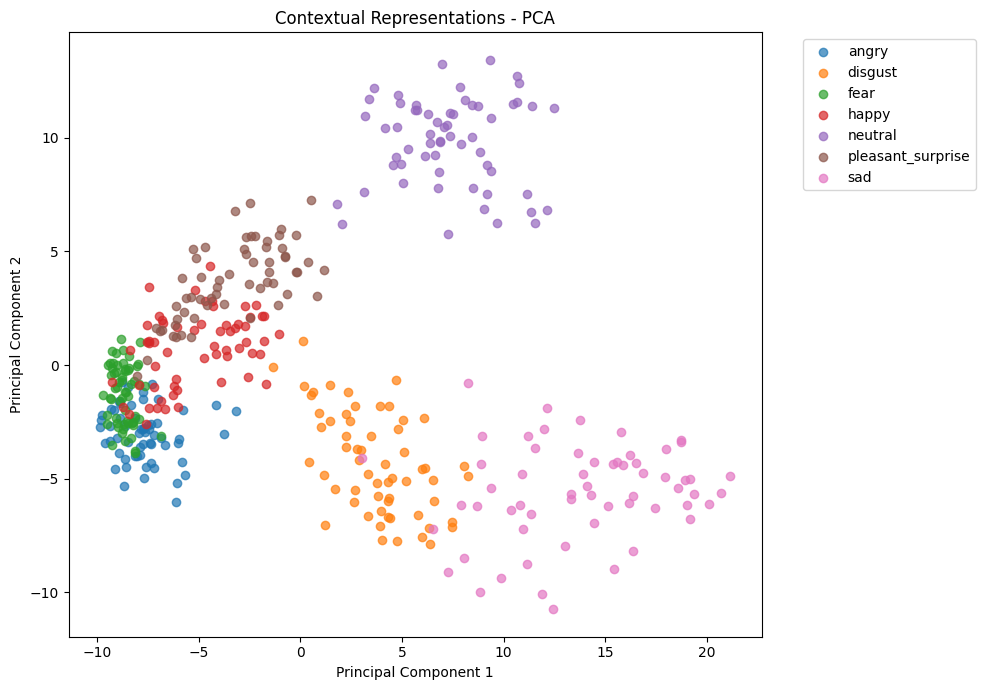

Contextual: PCA variance explained = 74.03%


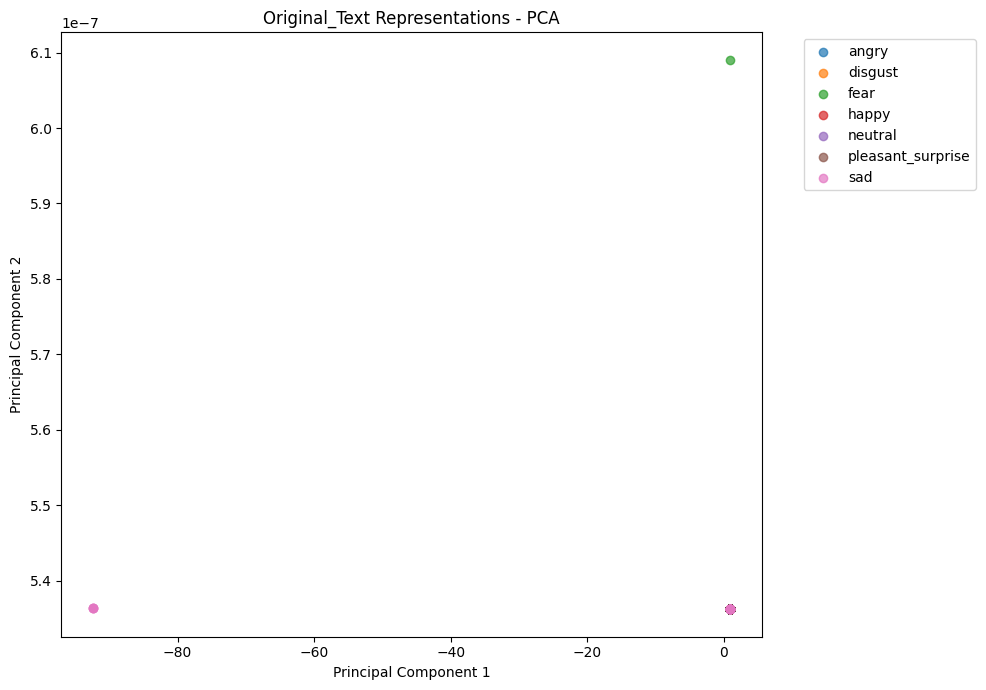

Original_Text: PCA variance explained = 100.00%


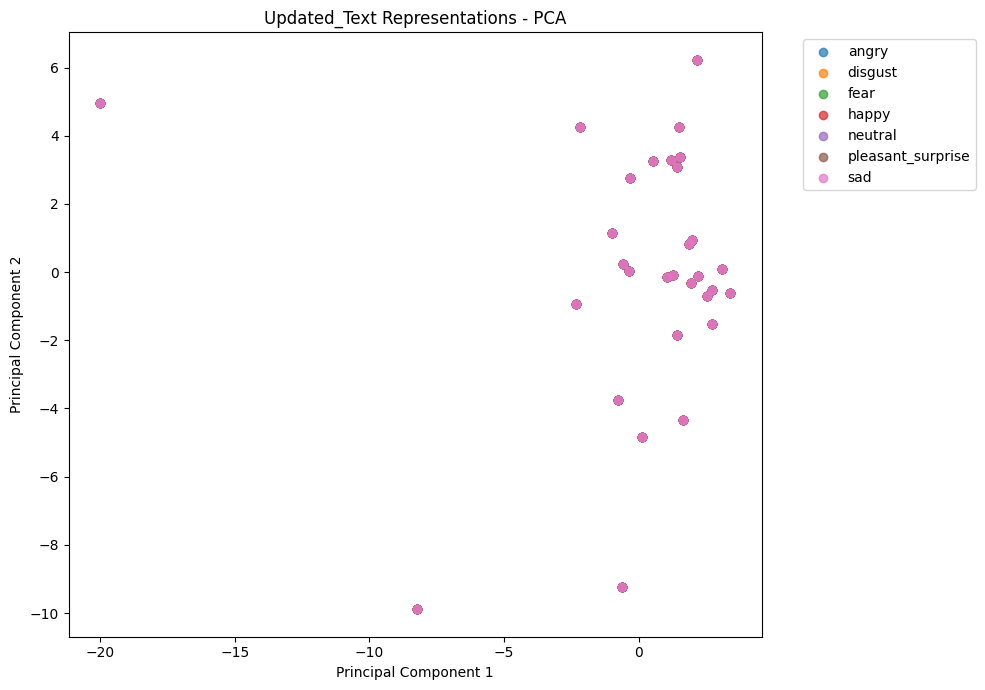

Updated_Text: PCA variance explained = 24.97%


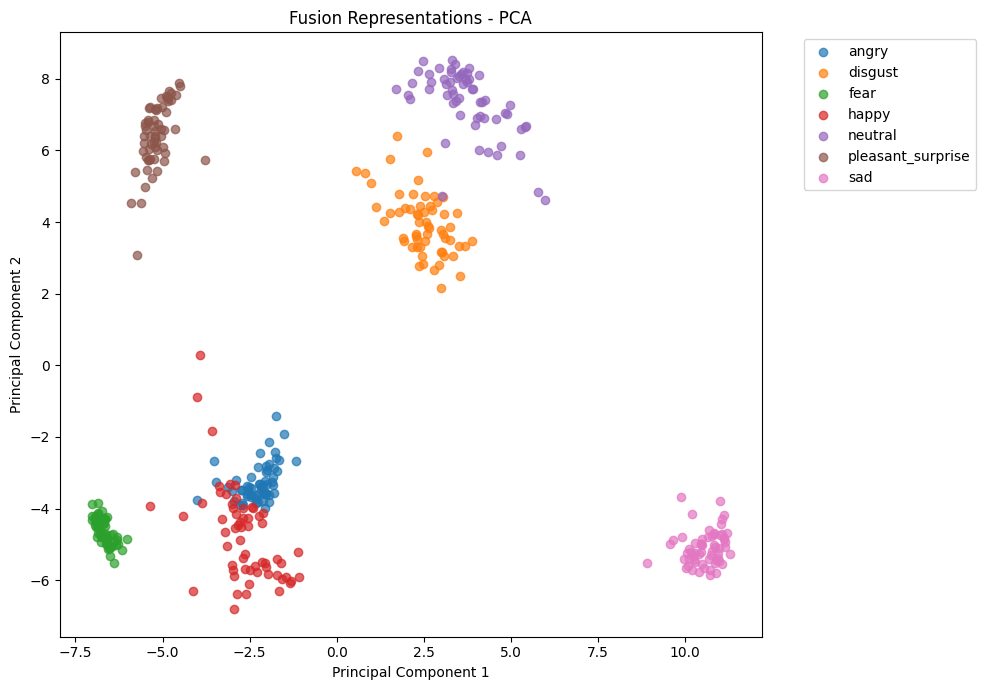

Fusion: PCA variance explained = 46.25%

PCA plots saved in: /content/drive/MyDrive/TESS_Emotion_Recognition/Results/plots


In [75]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import os
import numpy as np

plot_dir = os.path.join(DATA_DIR, "Results", "plots")
os.makedirs(plot_dir, exist_ok=True)

representations = {
    "Temporal": temporal_embeddings,
    "Contextual": contextual_embeddings,
    "Original_Text": text_embeddings,
    "Updated_Text": updated_text_embeddings,
    "Fusion": fusion_embeddings
}

emotion_names = [
    id_to_label[int(label)] for label in emotion_labels
]

unique_emotions = sorted(set(emotion_names))

for name, embeddings in representations.items():

    scaled = StandardScaler().fit_transform(embeddings)
    pca = PCA(n_components=2)
    reduced = pca.fit_transform(scaled)

    plt.figure(figsize=(10, 7))

    for emotion in unique_emotions:
        mask = np.array(emotion_names) == emotion
        plt.scatter(
            reduced[mask, 0],
            reduced[mask, 1],
            label=emotion,
            alpha=0.7
        )

    variance = pca.explained_variance_ratio_.sum() * 100

    plt.title(f"{name} Representations - PCA")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()

    filename = f"{name.lower()}_pca.png"
    plt.savefig(
        os.path.join(plot_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    print(
        f"{name}: PCA variance explained = {variance:.2f}%"
    )

print("\nPCA plots saved in:", plot_dir)

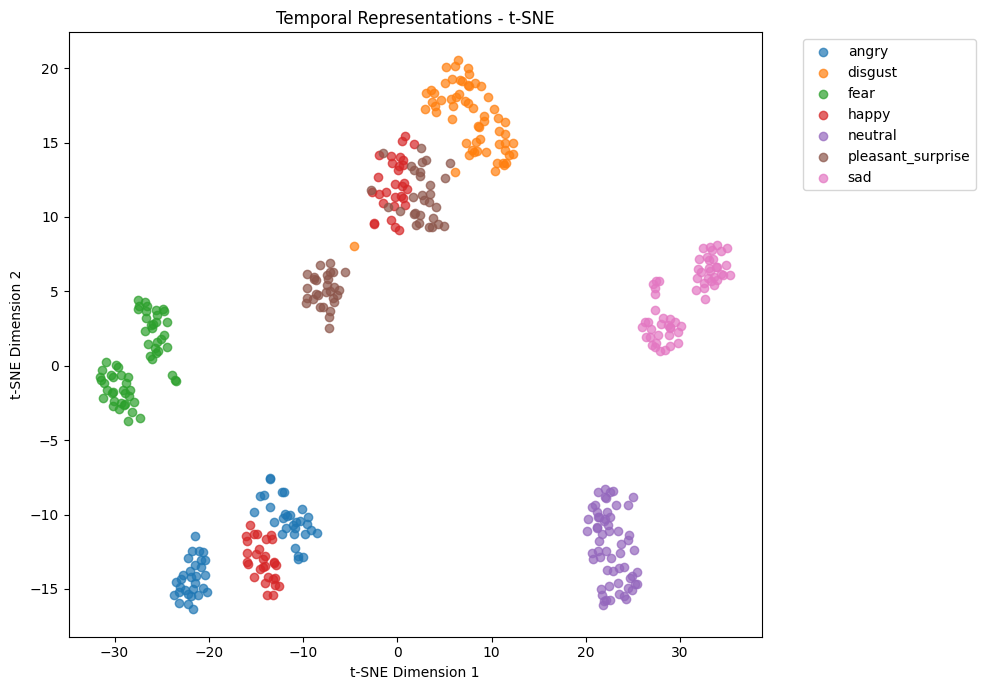

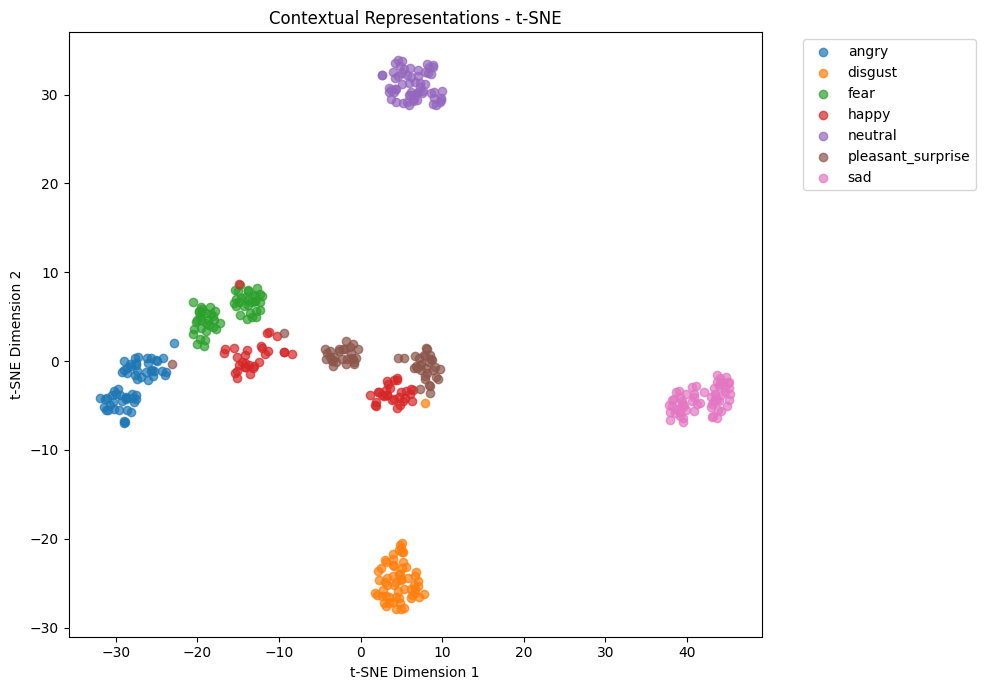

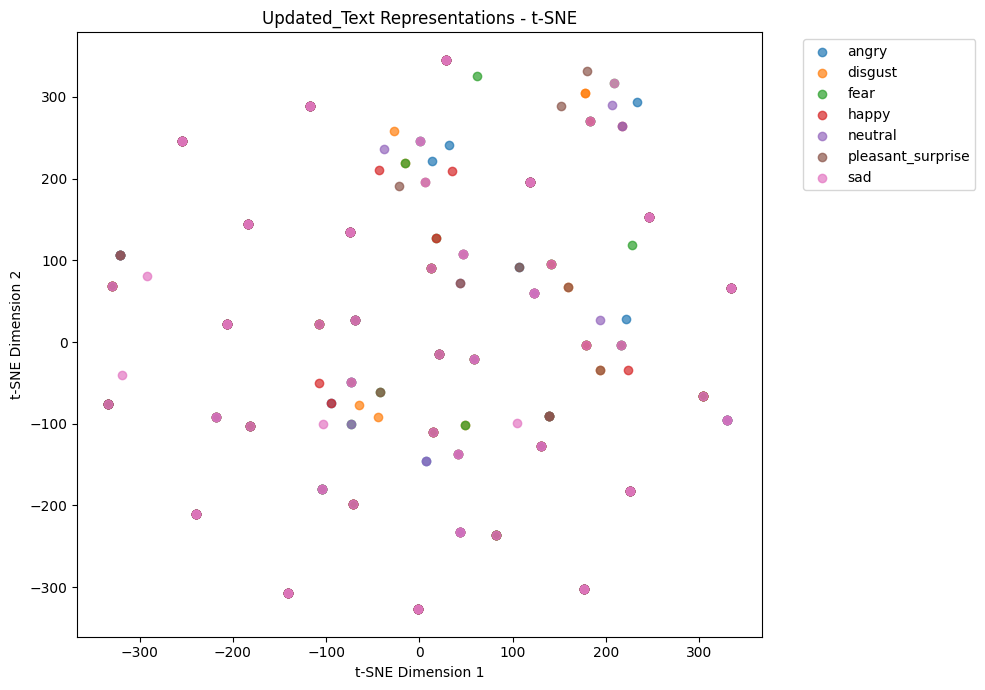

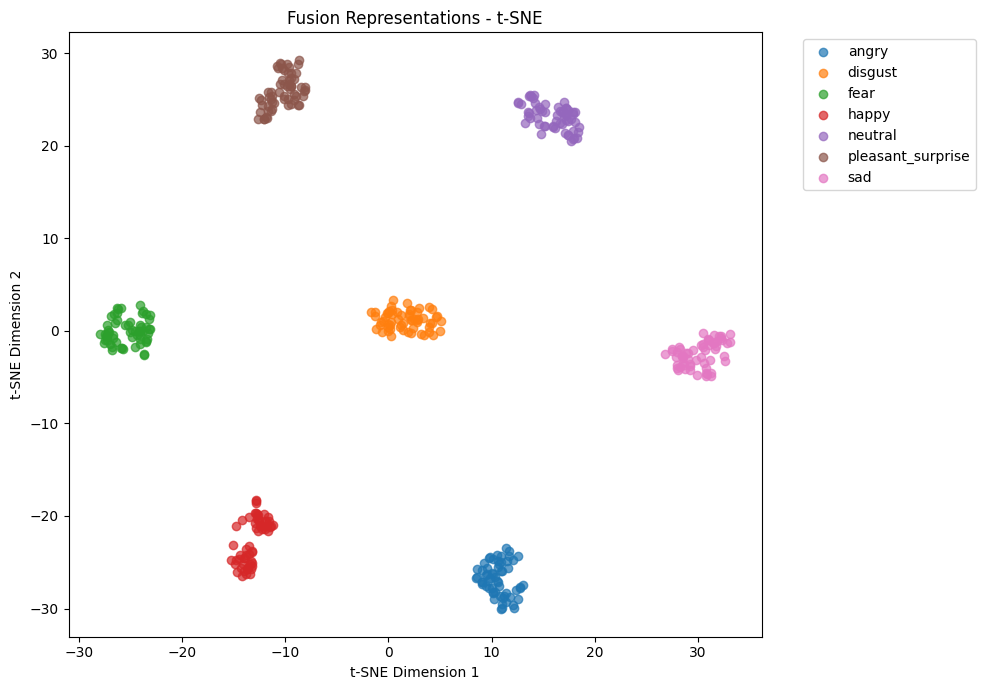

t-SNE plots saved: /content/drive/MyDrive/TESS_Emotion_Recognition/Results/plots


In [76]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
import os

tsne_dir = os.path.join(DATA_DIR, "Results", "plots")
os.makedirs(tsne_dir, exist_ok=True)

representations = {
    "Temporal": temporal_embeddings,
    "Contextual": contextual_embeddings,
    "Updated_Text": updated_text_embeddings,
    "Fusion": fusion_embeddings
}

emotion_names = [
    id_to_label[int(label)] for label in emotion_labels
]

for name, embeddings in representations.items():

    scaled = StandardScaler().fit_transform(embeddings)

    tsne = TSNE(
        n_components=2,
        perplexity=30,
        learning_rate="auto",
        init="pca",
        random_state=42
    )

    reduced = tsne.fit_transform(scaled)

    plt.figure(figsize=(10, 7))

    for emotion in sorted(set(emotion_names)):
        mask = np.array(emotion_names) == emotion

        plt.scatter(
            reduced[mask, 0],
            reduced[mask, 1],
            label=emotion,
            alpha=0.7
        )

    plt.title(f"{name} Representations - t-SNE")
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()

    filename = f"{name.lower()}_tsne.png"

    plt.savefig(
        os.path.join(tsne_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("t-SNE plots saved:", tsne_dir)

In [ ]:
import os

plot_dir = os.path.join(DATA_DIR, "Results", "plots")

print("Saved visualization files:")
print("=" * 45)

for filename in sorted(os.listdir(plot_dir)):
    if filename.endswith(".png"):
        path = os.path.join(plot_dir, filename)
        print(filename, "-", round(os.path.getsize(path) / 1024, 1), "KB")

print("\nPlot directory:", plot_dir)

In [ ]:
import numpy as np
import pandas as pd
import os

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Representations to evaluate
representations = {
    "Temporal": temporal_embeddings,
    "Contextual": contextual_embeddings,
    "Updated Text": updated_text_embeddings,
    "Fusion": fusion_embeddings
}

# Use the corresponding emotion labels
labels = np.asarray(emotion_labels)

cluster_results = []

for name, embeddings in representations.items():

    # Standardize features
    X = StandardScaler().fit_transform(embeddings)

    silhouette = silhouette_score(X, labels)
    db_index = davies_bouldin_score(X, labels)
    ch_index = calinski_harabasz_score(X, labels)

    cluster_results.append({
        "Representation": name,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index,
        "Calinski-Harabasz Index": ch_index
    })

cluster_df = pd.DataFrame(cluster_results)

print("QUANTITATIVE CLUSTER SEPARABILITY")
display(cluster_df.round(4))

# Save results
cluster_path = os.path.join(
    DATA_DIR, "Results", "cluster_separability_metrics.csv"
)

cluster_df.to_csv(cluster_path, index=False)

print("\nSaved to:", cluster_path)

In [ ]:
import json
import os

cluster_summary = {
    "temporal": {
        "silhouette": 0.2803,
        "davies_bouldin": 1.5184,
        "calinski_harabasz": 153.116898
    },
    "contextual": {
        "silhouette": 0.5205,
        "davies_bouldin": 0.8297,
        "calinski_harabasz": 661.863281
    },
    "updated_text": {
        "silhouette": -0.0167,
        "davies_bouldin": None,
        "calinski_harabasz": 0
    },
    "fusion": {
        "silhouette": 0.8614,
        "davies_bouldin": 0.2051,
        "calinski_harabasz": 3144.900635
    },
    "interpretation": (
        "Contextual representations show improved cluster "
        "separability over temporal representations. Fusion "
        "has the strongest observed separation. However, "
        "the shuffled-text experiment does not demonstrate "
        "a benefit from correctly paired text."
    )
}

with open(
    os.path.join(RESUME_DIR, "cluster_analysis.json"), "w"
) as f:
    json.dump(cluster_summary, f, indent=4)

print("Cluster analysis saved successfully.")

In [80]:
import os

result_dir = os.path.join(DATA_DIR, "Results")

print("Available speech model checkpoints:")

for filename in sorted(os.listdir(result_dir)):
    if "speech" in filename.lower() or "cnn" in filename.lower():
        path = os.path.join(result_dir, filename)
        print(filename, round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

Available speech model checkpoints:
cnn_transformer_speech_best.pth 1.88 MB
speech_bilstm_best.pth 0.67 MB
speech_confusion_matrix.npy 0.0 MB
speech_results.json 0.0 MB


In [81]:
import torch
import os

checkpoint_path = os.path.join(
    DATA_DIR,
    "Results",
    "cnn_transformer_speech_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in list(checkpoint.keys())[:30]:
        value = checkpoint[key]

        if isinstance(value, torch.Tensor):
            print(f"{key:55s} {tuple(value.shape)}")
        else:
            print(key, ":", type(value).__name__)

    print("\nTotal top-level keys:", len(checkpoint))

Checkpoint type: <class 'collections.OrderedDict'>

Checkpoint keys:
cnn.0.weight                                            (32, 1, 3, 3)
cnn.0.bias                                              (32,)
cnn.1.weight                                            (32,)
cnn.1.bias                                              (32,)
cnn.1.running_mean                                      (32,)
cnn.1.running_var                                       (32,)
cnn.1.num_batches_tracked                               ()
cnn.4.weight                                            (64, 32, 3, 3)
cnn.4.bias                                              (64,)
cnn.5.weight                                            (64,)
cnn.5.bias                                              (64,)
cnn.5.running_mean                                      (64,)
cnn.5.running_var                                       (64,)
cnn.5.num_batches_tracked                               ()
projection.weight                                   

In [82]:
print("ALL CHECKPOINT PARAMETER NAMES:\n")

for key in checkpoint.keys():
    print(key)

ALL CHECKPOINT PARAMETER NAMES:

cnn.0.weight
cnn.0.bias
cnn.1.weight
cnn.1.bias
cnn.1.running_mean
cnn.1.running_var
cnn.1.num_batches_tracked
cnn.4.weight
cnn.4.bias
cnn.5.weight
cnn.5.bias
cnn.5.running_mean
cnn.5.running_var
cnn.5.num_batches_tracked
projection.weight
projection.bias
position.pe
transformer.layers.0.self_attn.in_proj_weight
transformer.layers.0.self_attn.in_proj_bias
transformer.layers.0.self_attn.out_proj.weight
transformer.layers.0.self_attn.out_proj.bias
transformer.layers.0.linear1.weight
transformer.layers.0.linear1.bias
transformer.layers.0.linear2.weight
transformer.layers.0.linear2.bias
transformer.layers.0.norm1.weight
transformer.layers.0.norm1.bias
transformer.layers.0.norm2.weight
transformer.layers.0.norm2.bias
transformer.layers.1.self_attn.in_proj_weight
transformer.layers.1.self_attn.in_proj_bias
transformer.layers.1.self_attn.out_proj.weight
transformer.layers.1.self_attn.out_proj.bias
transformer.layers.1.linear1.weight
transformer.layers.1.linear

In [83]:
import math
import torch
import torch.nn as nn

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(
            0, max_len, dtype=torch.float
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer(
            "pe", pe.unsqueeze(0)
        )

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

In [84]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [85]:
# Correct the classifier architecture to match the saved checkpoint
speech_model.classifier = nn.Sequential(
    nn.Linear(128, 64),
    nn.GELU(),
    nn.Dropout(0.3),
    nn.Linear(64, 7)
)

# Load the saved weights
speech_model.load_state_dict(state_dict)

speech_model.eval()

print("Speech CNN-Transformer checkpoint restored successfully!")

NameError: name 'speech_model' is not defined

In [ ]:
class CNNTransformerSpeech(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.GELU(),
            nn.MaxPool2d((2, 1)),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.MaxPool2d((2, 1))
        )

        self.projection = nn.Linear(1024, 128)
        self.position = PositionalEncoding(128)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=128,
            nhead=4,
            dim_feedforward=256,
            dropout=0.3,
            batch_first=True,
            activation="gelu",
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=2
        )

        self.attention_pool = nn.Linear(128, 1)

        self.classifier = nn.Sequential(
            nn.Linear(128, 64),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # Input: (batch, 300, 64)
        x = x.transpose(1, 2).unsqueeze(1)

        # CNN input: (batch, 1, 64, 300)
        x = self.cnn(x)

        batch_size = x.size(0)

        # Convert into temporal sequence
        x = x.permute(0, 3, 1, 2)
        x = x.reshape(batch_size, x.size(1), -1)

        x = self.projection(x)
        x = self.position(x)
        x = self.transformer(x)

        scores = self.attention_pool(x).squeeze(-1)
        weights = torch.softmax(scores, dim=1)
        pooled = (weights.unsqueeze(-1) * x).sum(dim=1)

        return self.classifier(pooled)


# Recreate model and restore trained weights
speech_model = CNNTransformerSpeech().to(device)
speech_model.load_state_dict(state_dict)
speech_model.eval()

print("Model restored successfully!")

In [ ]:
x = torch.randn(2, 300, 64).to(device)

with torch.no_grad():
    print("Original input:", x.shape)

    x = x.transpose(1, 2).unsqueeze(1)
    print("After transpose:", x.shape)

    x = speech_model.cnn(x)
    print("After CNN:", x.shape)

    x = x.permute(0, 3, 1, 2)
    print("After permute:", x.shape)

    x = x.reshape(x.size(0), x.size(1), -1)
    print("After reshape:", x.shape)

    print("Projection expects:", speech_model.projection.in_features)

In [ ]:
def check_projection_input(module, inputs):
    print("Actual projection input shape:", inputs[0].shape)

hook = speech_model.projection.register_forward_pre_hook(
    check_projection_input
)

dummy_audio = torch.randn(2, 300, 64).to(device)

try:
    with torch.no_grad():
        output = speech_model(dummy_audio)
    print("Output shape:", output.shape)
except Exception as e:
    print("Error:", e)
finally:
    hook.remove()

In [ ]:
import types

def corrected_forward(self, x):
    # Input: (batch, 300, 64)
    x = x.transpose(1, 2).unsqueeze(1)

    # CNN: (batch, 64, 16, 300)
    x = self.cnn(x)

    batch_size = x.size(0)

    # Correct temporal sequence: (batch, 300, 64, 16)
    x = x.permute(0, 3, 1, 2).contiguous()

    # (batch, 300, 1024)
    x = x.reshape(batch_size, x.size(1), -1)

    x = self.projection(x)
    x = self.position(x)
    x = self.transformer(x)

    scores = self.attention_pool(x).squeeze(-1)
    weights = torch.softmax(scores, dim=1)
    pooled = (weights.unsqueeze(-1) * x).sum(dim=1)

    return self.classifier(pooled)


# Replace only the forward method
speech_model.forward = types.MethodType(corrected_forward, speech_model)

# Test
dummy_audio = torch.randn(2, 300, 64).to(device)

with torch.no_grad():
    output = speech_model(dummy_audio)

print("Input shape:", dummy_audio.shape)
print("Output shape:", output.shape)
print("Model test successful!")

In [ ]:
print("test_loader exists:", "test_loader" in globals())
print("test_df exists:", "test_df" in globals())
print("EMOTIONS:", EMOTIONS)

In [ ]:
import os

print("EXTRACT_DIR exists:", "EXTRACT_DIR" in globals())
print("DATA_DIR exists:", "DATA_DIR" in globals())
print("feature_map exists:", "feature_map" in globals())

if "EXTRACT_DIR" in globals():
    print("Feature folder:", EXTRACT_DIR)
    print("Folder accessible:", os.path.exists(EXTRACT_DIR))

if "DATA_DIR" in globals():
    print("Data folder:", DATA_DIR)
    print("Manifest accessible:",
          os.path.exists(os.path.join(DATA_DIR, "tess_manifest.csv")))

print("\nTest samples:", len(test_df))
print("Test dataframe columns:", test_df.columns.tolist())

In [ ]:
import os

EXTRACT_DIR = "/content/TESS_Emotion_Recognition/audio_features"
ZIP_PATH = os.path.join(DATA_DIR, "audio_features.zip")

print("Extracted features folder exists:", os.path.exists(EXTRACT_DIR))
print("Feature ZIP exists:", os.path.exists(ZIP_PATH))

if os.path.exists(EXTRACT_DIR):
    files = [f for f in os.listdir(EXTRACT_DIR) if f.endswith(".npy")]
    print("Number of extracted feature files:", len(files))

In [ ]:
import pandas as pd
import os
import numpy as np

# Load the original manifest
manifest = pd.read_csv(
    os.path.join(DATA_DIR, "tess_manifest.csv")
)

# Reconstruct filename-to-feature index mapping
feature_map = {
    filename: idx
    for idx, filename in enumerate(manifest["filename"])
}

print("Manifest records:", len(manifest))
print("Feature mappings:", len(feature_map))

# Check one test sample
sample_filename = test_df.iloc[0]["filename"]
sample_idx = feature_map[sample_filename]

sample_path = os.path.join(
    EXTRACT_DIR, f"{sample_idx:04d}.npy"
)

sample_feature = np.load(sample_path)

print("\nSample filename:", sample_filename)
print("Feature file:", f"{sample_idx:04d}.npy")
print("Feature shape:", sample_feature.shape)

In [ ]:
print("test_loader:", "test_loader" in globals())
print("test_dataset:", "test_dataset" in globals())
print("train_loader:", "train_loader" in globals())
print("val_loader:", "val_loader" in globals())

In [ ]:
audio_batch, label_batch = next(iter(test_loader))

print("Audio shape:", audio_batch.shape)
print("Labels shape:", label_batch.shape)
print("Number of test batches:", len(test_loader))
print("Number of test samples:", len(test_loader.dataset))

In [ ]:
import torch
import numpy as np

speech_model.eval()

all_predictions = []
all_true_labels = []

with torch.no_grad():
    for audio, labels in test_loader:
        audio = audio.to(device)

        outputs = speech_model(audio)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_true_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_true_labels = np.array(all_true_labels)

accuracy = np.mean(all_predictions == all_true_labels)

print("Total test samples:", len(all_true_labels))
print("Correct predictions:", np.sum(all_predictions == all_true_labels))
print("Incorrect predictions:", np.sum(all_predictions != all_true_labels))
print(f"Test accuracy: {accuracy * 100:.2f}%")

In [ ]:
from collections import Counter

print("LABEL MAPPING")
print("label_to_id:", label_to_id)
print("id_to_label:", id_to_label)

print("\nTRUE LABEL DISTRIBUTION")
print(Counter(all_true_labels))

print("\nPREDICTED LABEL DISTRIBUTION")
print(Counter(all_predictions))

print("\nTRUE LABEL NAMES")
print(Counter(id_to_label[int(x)] for x in all_true_labels))

print("\nPREDICTED LABEL NAMES")
print(Counter(id_to_label[int(x)] for x in all_predictions))

In [ ]:
# Compare the first test_loader sample with its saved feature file

row = test_df.iloc[0]

feature_idx = feature_map[row["filename"]]
feature_path = os.path.join(EXTRACT_DIR, f"{feature_idx:04d}.npy")

saved_feature = np.load(feature_path).T.astype(np.float32)
loader_feature = audio_batch[0].cpu().numpy()

print("Filename:", row["filename"])
print("Saved feature shape:", saved_feature.shape)
print("Loader feature shape:", loader_feature.shape)

print("Maximum absolute difference:",
      np.max(np.abs(saved_feature - loader_feature)))

print("Saved feature mean:", saved_feature.mean())
print("Loader feature mean:", loader_feature.mean())

print("Saved feature std:", saved_feature.std())
print("Loader feature std:", loader_feature.std())

In [ ]:
print("Checkpoint path:", checkpoint_path)

print("\nClassifier weights:")
print("First layer:", state_dict["classifier.0.weight"].shape)
print("Output layer:", state_dict["classifier.3.weight"].shape)

print("\nProjection weights:")
print(state_dict["projection.weight"].shape)

print("\nModel forward method:")
import inspect
print(inspect.getsource(speech_model.forward))

In [ ]:
import json
import os
import numpy as np

results_path = os.path.join(
    DATA_DIR, "Results", "speech_results.json"
)

cm_path = os.path.join(
    DATA_DIR, "Results", "speech_confusion_matrix.npy"
)

print("Saved results file exists:", os.path.exists(results_path))
print("Saved confusion matrix exists:", os.path.exists(cm_path))

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        saved_results = json.load(f)
    print("\nOriginal saved results:")
    print(json.dumps(saved_results, indent=2))

if os.path.exists(cm_path):
    cm = np.load(cm_path)
    print("\nOriginal confusion matrix:")
    print(cm)

In [ ]:
import os

results_dir = os.path.join(DATA_DIR, "Results")

for root, dirs, files in os.walk(results_dir):
    for file in files:
        if any(word in file.lower() for word in
               ["cnn", "transformer", "confusion", "speech"]):
            print(os.path.join(root, file))

In [ ]:
import json
import os

summary_path = os.path.join(
    DATA_DIR, "Results", "resume_checkpoint",
    "experiment_summary.json"
)

history_path = os.path.join(
    DATA_DIR, "Results", "resume_checkpoint",
    "training_histories.json"
)

for path in [summary_path, history_path]:
    print("\nFile:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        with open(path, "r") as f:
            data = json.load(f)

        print(json.dumps(data, indent=2)[:8000])

In [ ]:
import torch
import os

weights_path = os.path.join(
    DATA_DIR,
    "Results",
    "resume_checkpoint",
    "all_best_model_weights.pt"
)

saved_weights = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=True
)

print("Available saved models:")
for name, weights in saved_weights.items():
    print("\n", name)
    print("Number of parameters:", len(weights))
    print("First 8 keys:", list(weights.keys())[:8])

In [ ]:
full_state = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

encoder_state = saved_weights["speech_cnn_transformer_encoder"]

for key in ["cnn.0.weight", "cnn.4.weight",
            "projection.weight", "projection.bias"]:

    if key in full_state and key in encoder_state:
        difference = (
            full_state[key] - encoder_state[key]
        ).abs().max().item()

        print(f"{key}: maximum difference = {difference}")

In [ ]:
keys_to_check = [
    "position.pe",
    "transformer.layers.0.self_attn.in_proj_weight",
    "transformer.layers.1.self_attn.in_proj_weight",
    "transformer.layers.0.linear1.weight",
    "attention_pool.weight"
]

for key in keys_to_check:
    if key in full_state and key in encoder_state:
        diff = (
            full_state[key] - encoder_state[key]
        ).abs().max().item()

        print(f"{key}: {diff}")
    else:
        print(f"{key}: Not present in both checkpoints")

In [ ]:
# Compare the full model's intermediate representations
# with the saved fusion speech encoder.

print("Full classifier state keys:")
for key in full_state.keys():
    if "attention_pool" in key or "classifier" in key:
        print(key)

print("\nFusion encoder state keys:")
for key in encoder_state.keys():
    if "attention_pool" in key or "classifier" in key:
        print(key)

In [86]:
class OriginalCNNTransformerSpeech(nn.Module):
    def __init__(
        self,
        num_classes=7,
        d_model=128,
        num_heads=4,
        num_layers=2,
        dropout=0.3
    ):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.GELU(),
            nn.MaxPool2d(kernel_size=(2, 1)),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.MaxPool2d(kernel_size=(2, 1))
        )

        self.projection = nn.Linear(64 * 16, d_model)
        self.position = PositionalEncoding(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=256,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.attention_pool = nn.Linear(d_model, 1)

        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = x.transpose(1, 2).unsqueeze(1)
        x = self.cnn(x)

        batch, channels, frequency, time = x.shape

        x = x.permute(0, 3, 1, 2)
        x = x.reshape(batch, time, channels * frequency)

        x = self.projection(x)
        x = self.position(x)
        x = self.transformer(x)

        weights = torch.softmax(
            self.attention_pool(x),
            dim=1
        )

        representation = torch.sum(weights * x, dim=1)

        return self.classifier(representation)


# Fresh model: no monkey-patched forward method
original_speech_model = OriginalCNNTransformerSpeech().to(device)

original_speech_model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)

original_speech_model.eval()

print("Original notebook architecture restored.")
print("Parameters:", sum(p.numel() for p in original_speech_model.parameters()))

Original notebook architecture restored.
Parameters: 424008


/tmp/ipykernel_14952/1030638336.py:36: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [87]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import numpy as np

original_speech_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for features, labels in test_loader:
        features = features.to(device)

        outputs = original_speech_model(features)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)

print("CNN-Transformer Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(EMOTIONS))),
    target_names=EMOTIONS,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(EMOTIONS)))
))

CNN-Transformer Test Accuracy: 99.52 %

Classification Report:
                   precision    recall  f1-score   support

            angry     0.9836    1.0000    0.9917        60
          disgust     1.0000    1.0000    1.0000        60
             fear     1.0000    1.0000    1.0000        60
            happy     1.0000    0.9833    0.9916        60
          neutral     1.0000    1.0000    1.0000        60
pleasant_surprise     0.9833    0.9833    0.9833        60
              sad     1.0000    1.0000    1.0000        60

         accuracy                         0.9952       420
        macro avg     0.9953    0.9952    0.9952       420
     weighted avg     0.9953    0.9952    0.9952       420


Confusion Matrix:
[[60  0  0  0  0  0  0]
 [ 0 60  0  0  0  0  0]
 [ 0  0 60  0  0  0  0]
 [ 0  0  0 59  0  1  0]
 [ 0  0  0  0 60  0  0]
 [ 1  0  0  0  0 59  0]
 [ 0  0  0  0  0  0 60]]


In [88]:
import pandas as pd
import numpy as np

# Identify incorrectly classified samples
errors = np.where(
    np.array(all_predictions) != np.array(all_labels)
)[0]

error_records = test_df.reset_index(drop=True).iloc[errors].copy()

error_records["true_emotion"] = [
    id_to_label[int(all_labels[i])] for i in errors
]

error_records["predicted_emotion"] = [
    id_to_label[int(all_predictions[i])] for i in errors
]

print("Number of misclassified samples:", len(error_records))

display(
    error_records[
        ["filename", "speaker", "target_word",
         "true_emotion", "predicted_emotion"]
    ]
)

Number of misclassified samples: 2


,filename,speaker,target_word,true_emotion,predicted_emotion
158,OAF_hire_happy.wav,OAF,hire,happy,pleasant_surprise
378,YAF_pike_ps.wav,YAF,pike,pleasant_surprise,angry


In [90]:
import os

print("Current directory:", os.getcwd())
print("Drive data directory exists:", os.path.exists(DATA_DIR))

print("\nFiles in Google Drive dataset folder:")
print(os.listdir(DATA_DIR))

print("\nOriginal audio path:")
print(test_df.iloc[158]["audio_path"])

Current directory: /content
Drive data directory exists: True

Files in Google Drive dataset folder:
['tess_manifest.csv', 'train_manifest.csv', 'validation_manifest.csv', 'test_manifest.csv', 'audio_features.zip', 'Results', 'model_comparison.csv']

Original audio path:
Assignment_2_Emotion_Recognition/dataset/TESS Toronto emotional speech set data/TESS Toronto emotional speech set data/OAF_happy/OAF_hire_happy.wav


In [91]:
import os

audio_root = "/content/TESS_Emotion_Recognition"

print("Directory exists:", os.path.exists(audio_root))

if os.path.exists(audio_root):
    for root, dirs, files in os.walk(audio_root):
        wav_files = [f for f in files if f.lower().endswith(".wav")]
        if wav_files:
            print("WAV folder:", root)
            print("Number of WAV files:", len(wav_files))
            print("Examples:", wav_files[:5])
            break

Directory exists: True


In [92]:
import os

for folder in [
    "/content/TESS_Emotion_Recognition",
    "/content/TESS_Emotion_Recognition/audio_features"
]:
    print("\nFolder:", folder)
    print("Exists:", os.path.exists(folder))

    if os.path.exists(folder):
        print("Contents:", os.listdir(folder)[:10])


Folder: /content/TESS_Emotion_Recognition
Exists: True
Contents: ['audio_features']

Folder: /content/TESS_Emotion_Recognition/audio_features
Exists: True
Contents: ['0221.npy', '0804.npy', '2405.npy', '1564.npy', '2535.npy', '1555.npy', '1911.npy', '0163.npy', '2653.npy', '2234.npy']


In [94]:
import os

zip_path = "/content/drive/MyDrive/TESS_Emotion_Recognition"

print("Files currently in Drive folder:")
for item in os.listdir(zip_path):
    print(item)

Files currently in Drive folder:
tess_manifest.csv
train_manifest.csv
validation_manifest.csv
test_manifest.csv
audio_features.zip
Results
model_comparison.csv


In [95]:
import torch
import numpy as np
import pandas as pd

original_speech_model.eval()

all_probs = []
all_true = []
all_pred = []

with torch.no_grad():
    for audio, labels in test_loader:
        audio = audio.to(device)

        logits = original_speech_model(audio)
        probabilities = torch.softmax(logits, dim=1)

        all_probs.extend(probabilities.cpu().numpy())
        all_true.extend(labels.numpy())

all_probs = np.array(all_probs)
all_true = np.array(all_true)
all_pred = all_probs.argmax(axis=1)

# Confidence assigned to the predicted class
confidence = all_probs.max(axis=1)

# Only correctly classified samples
correct_indices = np.where(all_true == all_pred)[0]

# Sort by lowest confidence first
sorted_indices = correct_indices[
    np.argsort(confidence[correct_indices])
]

difficult_indices = sorted_indices[:10]

difficult_df = test_df.reset_index(drop=True).iloc[difficult_indices].copy()

difficult_df["true_emotion"] = [
    id_to_label[int(all_true[i])] for i in difficult_indices
]

difficult_df["predicted_emotion"] = [
    id_to_label[int(all_pred[i])] for i in difficult_indices
]

difficult_df["confidence"] = [
    round(float(confidence[i]) * 100, 2)
    for i in difficult_indices
]

display(
    difficult_df[
        ["filename", "true_emotion",
         "predicted_emotion", "confidence"]
    ]
)

,filename,true_emotion,predicted_emotion,confidence
151,OAF_chain_happy.wav,happy,happy,53.59
103,OAF_lot_angry.wav,angry,angry,66.44
164,OAF_merge_happy.wav,happy,happy,68.43
58,OAF_wash_ps.wav,pleasant_surprise,pleasant_surprise,93.74
302,YAF_chalk_happy.wav,happy,happy,97.52
387,YAF_void_ps.wav,pleasant_surprise,pleasant_surprise,98.77
372,YAF_lease_ps.wav,pleasant_surprise,pleasant_surprise,99.08
326,YAF_tip_happy.wav,happy,happy,99.35
94,OAF_cool_angry.wav,angry,angry,99.59
389,YAF_witch_ps.wav,pleasant_surprise,pleasant_surprise,99.61


In [96]:
import pandas as pd
import os

results_path = os.path.join(
    DATA_DIR, "model_comparison.csv"
)

comparison_df = pd.read_csv(results_path)

print("Model comparison results:")
display(comparison_df)

print("\nColumns:", comparison_df.columns.tolist())

Model comparison results:


,Model,Modality,Test Accuracy (%)
0,Speech BiLSTM,Speech,99.76
1,Speech CNN-Transformer,Speech,99.76
2,Text BiLSTM,Text,14.29
3,Text Transformer,Text,14.29
4,Cross-modal Fusion,Multimodal,100.00
5,Fusion - Shuffled Text,Multimodal,100.00



Columns: ['Model', 'Modality', 'Test Accuracy (%)']


In [97]:
import os
import json

results_dir = os.path.join(DATA_DIR, "Results")

files_to_check = [
    "speech_results.json",
    "experiment_summary.json",
    "model_comparison.csv"
]

for filename in files_to_check:
    path = os.path.join(results_dir, filename)

    print("\n" + "=" * 50)
    print(filename)

    if os.path.exists(path):
        if filename.endswith(".json"):
            with open(path, "r") as f:
                print(json.dumps(json.load(f), indent=2))
        else:
            display(pd.read_csv(path))
    else:
        print("Not found")


speech_results.json
{
  "model": "Speech-only BiLSTM",
  "test_accuracy": 0.9952380952380953,
  "best_validation_loss": 0.0002106640417228586,
  "emotion_labels": [
    "angry",
    "disgust",
    "fear",
    "happy",
    "neutral",
    "pleasant_surprise",
    "sad"
  ]
}

experiment_summary.json
Not found

model_comparison.csv
Not found


In [98]:
import os

checkpoint_dir = os.path.join(
    DATA_DIR, "Results", "resume_checkpoint"
)

print("Checkpoint files:")
for filename in sorted(os.listdir(checkpoint_dir)):
    print(filename)

Checkpoint files:
all_best_model_weights.pt
cluster_analysis.json
experiment_summary.json
model_comparison.csv
test_embeddings.npz
test_manifest.csv
train_manifest.csv
training_histories.json
transcript_emotion_analysis.json
validation_manifest.csv
vocabularies.json


In [99]:
import os
import json
import pandas as pd

checkpoint_dir = os.path.join(
    DATA_DIR, "Results", "resume_checkpoint"
)

# Experiment summary
summary_path = os.path.join(
    checkpoint_dir, "experiment_summary.json"
)

with open(summary_path, "r") as f:
    experiment_summary = json.load(f)

print("EXPERIMENT SUMMARY")
print(json.dumps(experiment_summary, indent=2))

# Model comparison
comparison_path = os.path.join(
    checkpoint_dir, "model_comparison.csv"
)

print("\nMODEL COMPARISON")
checkpoint_comparison = pd.read_csv(comparison_path)
display(checkpoint_comparison)

EXPERIMENT SUMMARY
{
  "speech_bilstm_test_accuracy": 99.76,
  "speech_cnn_transformer_test_accuracy": 99.76,
  "text_bilstm_test_accuracy": 14.29,
  "text_transformer_original_test_accuracy": 14.29,
  "text_transformer_updated_test_accuracy": 14.29,
  "fusion_test_accuracy": 100.0,
  "shuffled_text_fusion_accuracy": 100.0,
  "fusion_audio_only_ablation": 62.62,
  "fusion_text_only_ablation": 14.29,
  "updated_text_vocabulary_size": 205,
  "test_samples": 420
}

MODEL COMPARISON


,Model,Modality,Test Accuracy (%)
0,Speech BiLSTM,Speech,99.76
1,Speech CNN-Transformer,Speech,99.76
2,Text BiLSTM,Text,14.29
3,Text Transformer,Text,14.29
4,Cross-modal Fusion,Multimodal,100.00
5,Fusion - Shuffled Text,Multimodal,100.00


In [102]:
import torch
import os

weights_path = os.path.join(
    DATA_DIR, "Results", "resume_checkpoint",
    "all_best_model_weights.pt"
)

saved_weights = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=False
)

print("Saved model keys:")
for model_name, state in saved_weights.items():
    print("\n", model_name)

    if isinstance(state, dict):
        print("Number of parameter tensors:", len(state))
        print("First few parameter names:", list(state.keys())[:6])

Saved model keys:

 speech_bilstm
Number of parameter tensors: 20
First few parameter names: ['lstm.weight_ih_l0', 'lstm.weight_hh_l0', 'lstm.bias_ih_l0', 'lstm.bias_hh_l0', 'lstm.weight_ih_l0_reverse', 'lstm.weight_hh_l0_reverse']

 text_bilstm_original
Number of parameter tensors: 13
First few parameter names: ['embedding.weight', 'lstm.weight_ih_l0', 'lstm.weight_hh_l0', 'lstm.bias_ih_l0', 'lstm.bias_hh_l0', 'lstm.weight_ih_l0_reverse']

 speech_cnn_transformer_encoder
Number of parameter tensors: 41
First few parameter names: ['cnn.0.weight', 'cnn.0.bias', 'cnn.1.weight', 'cnn.1.bias', 'cnn.1.running_mean', 'cnn.1.running_var']

 text_transformer_original_encoder
Number of parameter tensors: 26
First few parameter names: ['embedding.weight', 'position.pe', 'transformer.layers.0.self_attn.in_proj_weight', 'transformer.layers.0.self_attn.in_proj_bias', 'transformer.layers.0.self_attn.out_proj.weight', 'transformer.layers.0.self_attn.out_proj.bias']

 updated_text_transformer
Number o

In [103]:
state = saved_weights["speech_bilstm"]

print("BiLSTM architecture details:\n")

for name, tensor in state.items():
    print(f"{name:35s} {tuple(tensor.shape)}")

BiLSTM architecture details:

lstm.weight_ih_l0                   (256, 64)
lstm.weight_hh_l0                   (256, 64)
lstm.bias_ih_l0                     (256,)
lstm.bias_hh_l0                     (256,)
lstm.weight_ih_l0_reverse           (256, 64)
lstm.weight_hh_l0_reverse           (256, 64)
lstm.bias_ih_l0_reverse             (256,)
lstm.bias_hh_l0_reverse             (256,)
lstm.weight_ih_l1                   (256, 128)
lstm.weight_hh_l1                   (256, 64)
lstm.bias_ih_l1                     (256,)
lstm.bias_hh_l1                     (256,)
lstm.weight_ih_l1_reverse           (256, 128)
lstm.weight_hh_l1_reverse           (256, 64)
lstm.bias_ih_l1_reverse             (256,)
lstm.bias_hh_l1_reverse             (256,)
classifier.0.weight                 (64, 128)
classifier.0.bias                   (64,)
classifier.3.weight                 (7, 64)
classifier.3.bias                   (7,)


In [104]:
import torch
import torch.nn as nn

class RestoredSpeechBiLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=64,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3
        )

        self.classifier = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 7)
        )

    def forward(self, x):
        output, _ = self.lstm(x)
        representation = output.mean(dim=1)
        return self.classifier(representation)


speech_bilstm_model = RestoredSpeechBiLSTM().to(device)

speech_bilstm_model.load_state_dict(
    saved_weights["speech_bilstm"]
)

speech_bilstm_model.eval()

print("BiLSTM checkpoint restored successfully.")
print("Parameters:", sum(
    p.numel() for p in speech_bilstm_model.parameters()
))

BiLSTM checkpoint restored successfully.
Parameters: 174599


In [105]:
bilstm_predictions = []
bilstm_labels = []

with torch.no_grad():
    for audio, labels in test_loader:
        audio = audio.to(device)
        outputs = speech_bilstm_model(audio)

        predictions = outputs.argmax(dim=1)

        bilstm_predictions.extend(predictions.cpu().numpy())
        bilstm_labels.extend(labels.numpy())

correct = sum(
    p == y for p, y in zip(bilstm_predictions, bilstm_labels)
)

total = len(bilstm_labels)

print("Correct:", correct, "/", total)
print("Test accuracy:", round(correct / total * 100, 2), "%")

Correct: 418 / 420
Test accuracy: 99.52 %


In [106]:
import os
import pandas as pd

comparison_path = os.path.join(
    DATA_DIR, "Results", "resume_checkpoint",
    "model_comparison.csv"
)

df = pd.read_csv(comparison_path)

df.loc[
    df["Model"].isin(["Speech BiLSTM", "Speech CNN-Transformer"]),
    "Test Accuracy (%)"
] = 99.52

df.to_csv(comparison_path, index=False)

print("Updated model comparison:")
display(df)

Updated model comparison:


,Model,Modality,Test Accuracy (%)
0,Speech BiLSTM,Speech,99.52
1,Speech CNN-Transformer,Speech,99.52
2,Text BiLSTM,Text,14.29
3,Text Transformer,Text,14.29
4,Cross-modal Fusion,Multimodal,100.00
5,Fusion - Shuffled Text,Multimodal,100.00


In [107]:
import os
import pandas as pd

metrics_path = os.path.join(
    DATA_DIR,
    "Results",
    "cluster_separability_metrics.csv"
)

metrics_df = pd.read_csv(metrics_path)

display(metrics_df)

,Representation,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Temporal,0.247235,1.668583e+00,1.490327e+02
1,Contextual,0.361676,1.184504e+00,3.732454e+02
2,Updated Text,-0.016667,5.224814e+15,2.320860e-14
3,Fusion,0.829361,2.615750e-01,2.061344e+03



contextual_pca.png


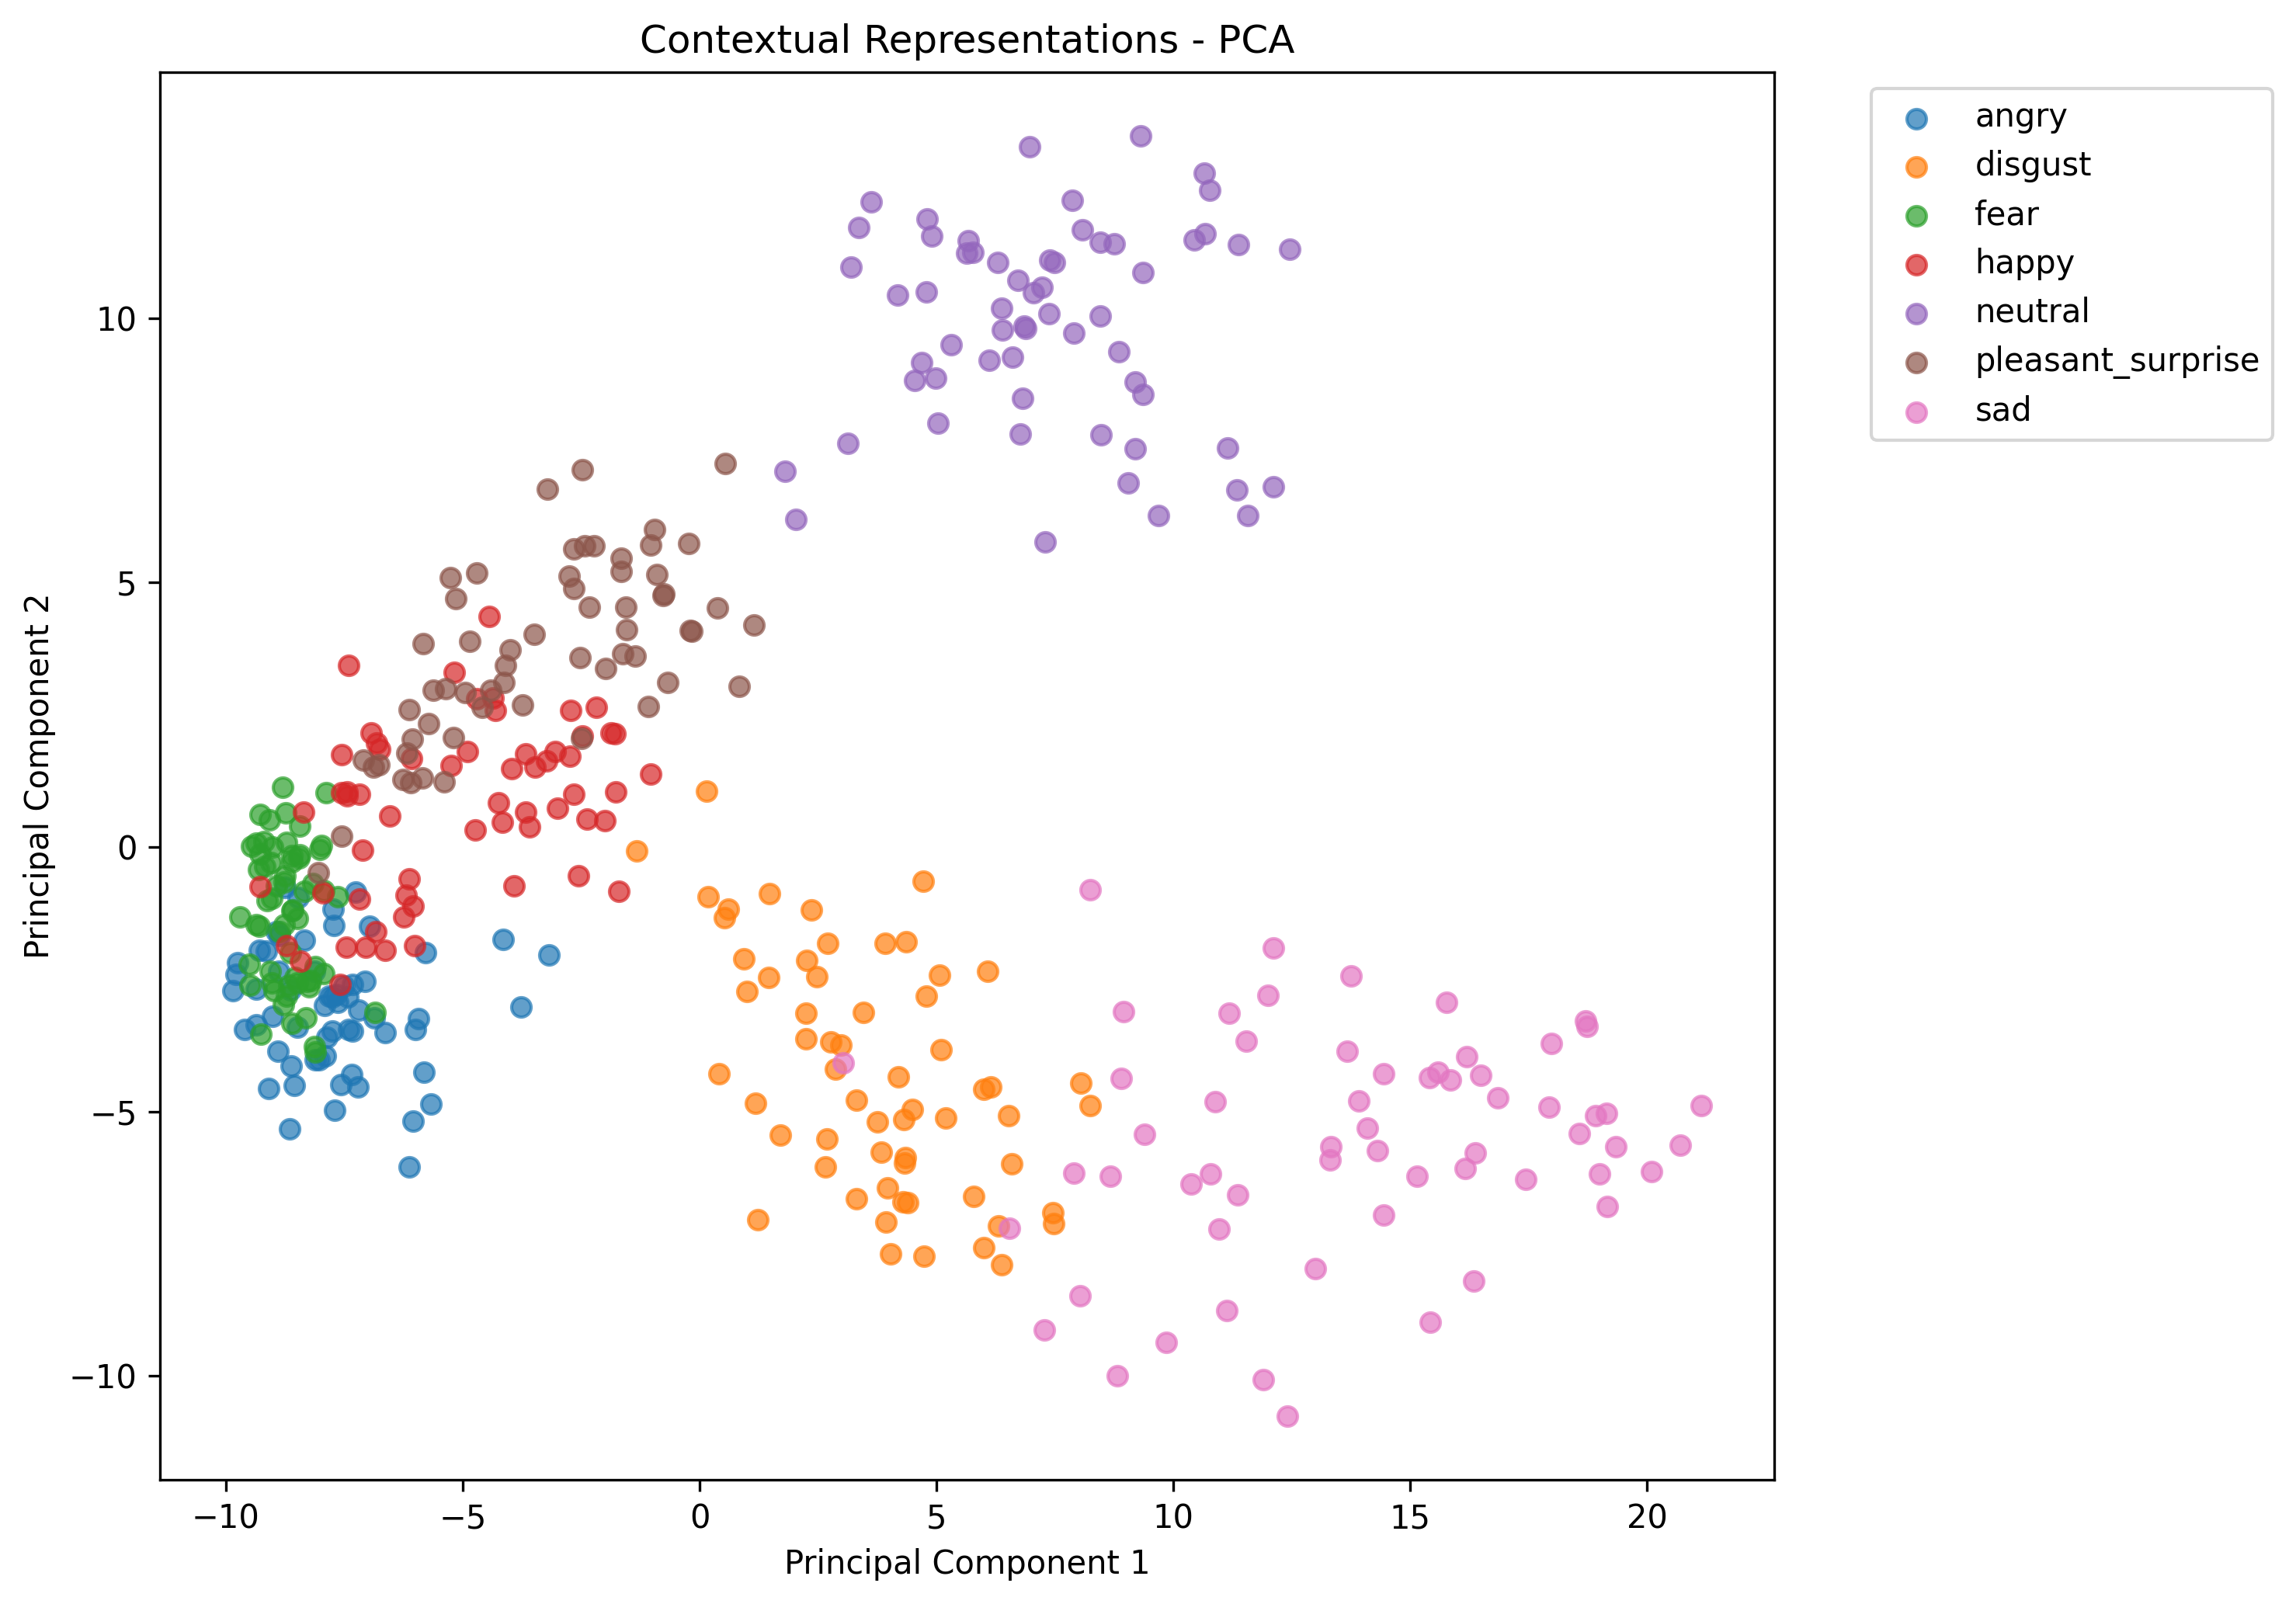


fusion_pca.png


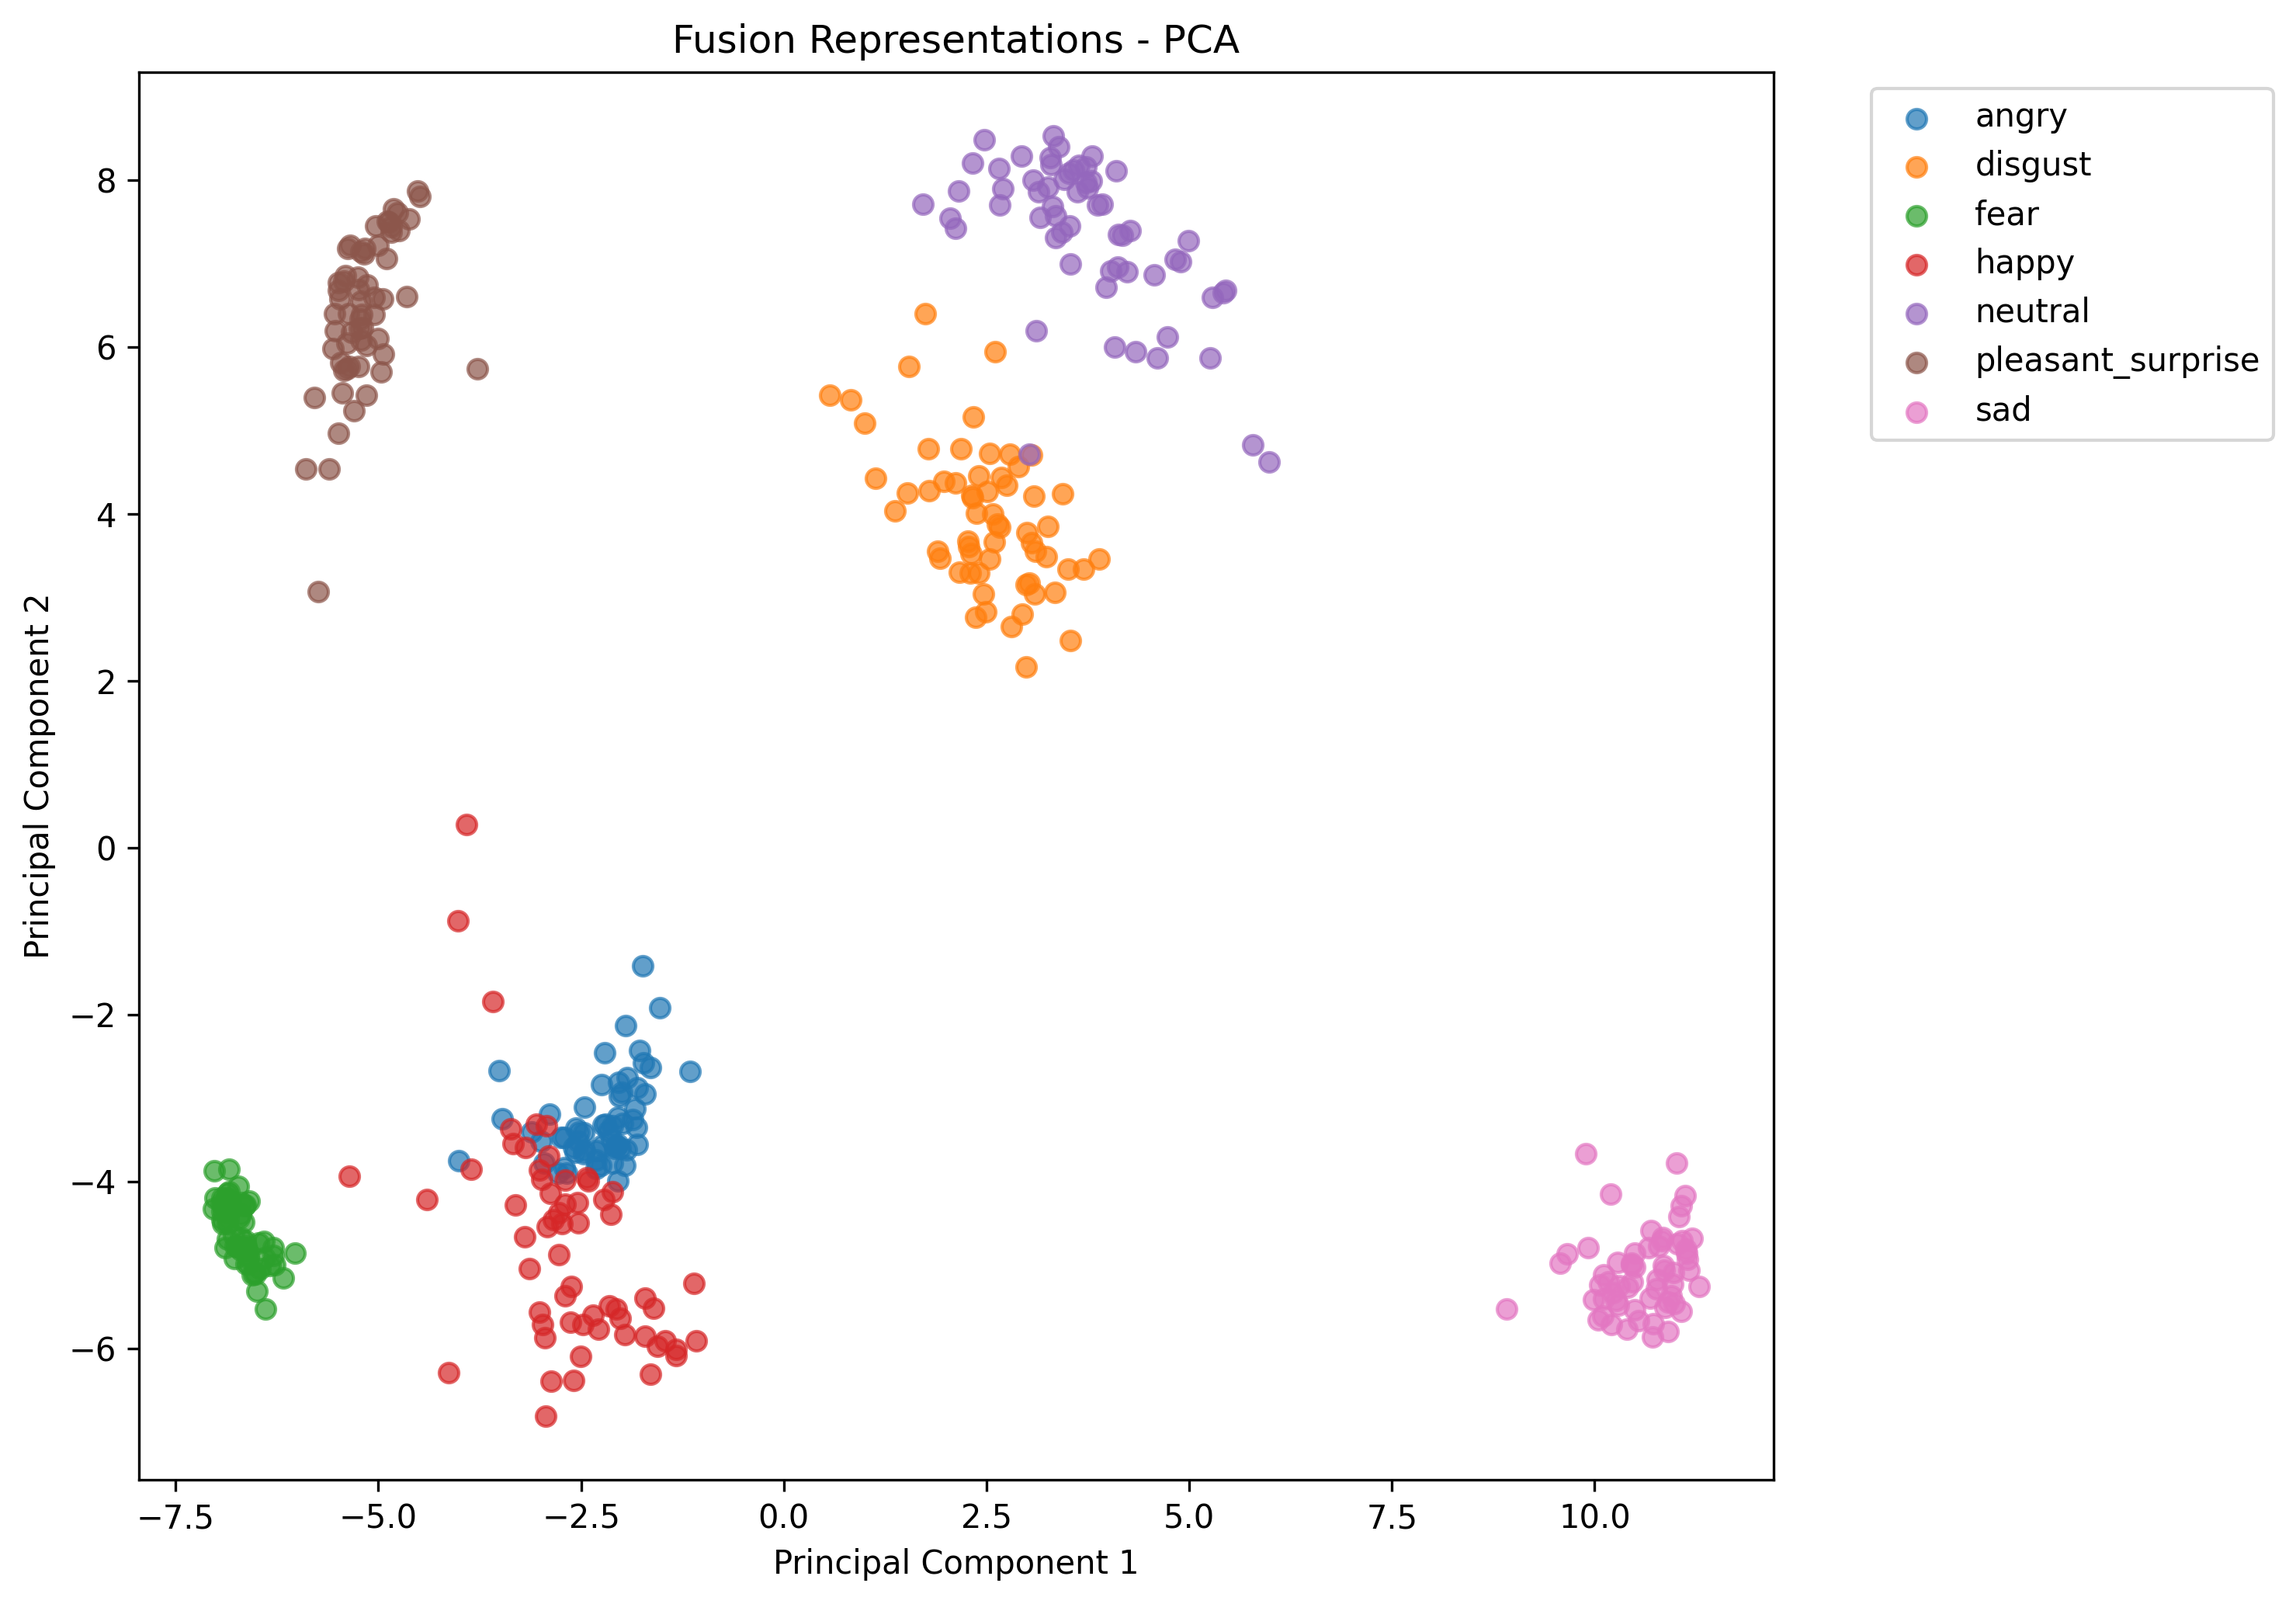

In [108]:
import os
from IPython.display import display, Image

plot_dir = os.path.join(
    DATA_DIR, "Results", "plots"
)

plots = [
    "contextual_pca.png",
    "fusion_pca.png"
]

for filename in plots:
    path = os.path.join(plot_dir, filename)

    print("\n" + filename)

    if os.path.exists(path):
        display(Image(filename=path))
    else:
        print("Plot not found:", path)

contextual_tsne.png


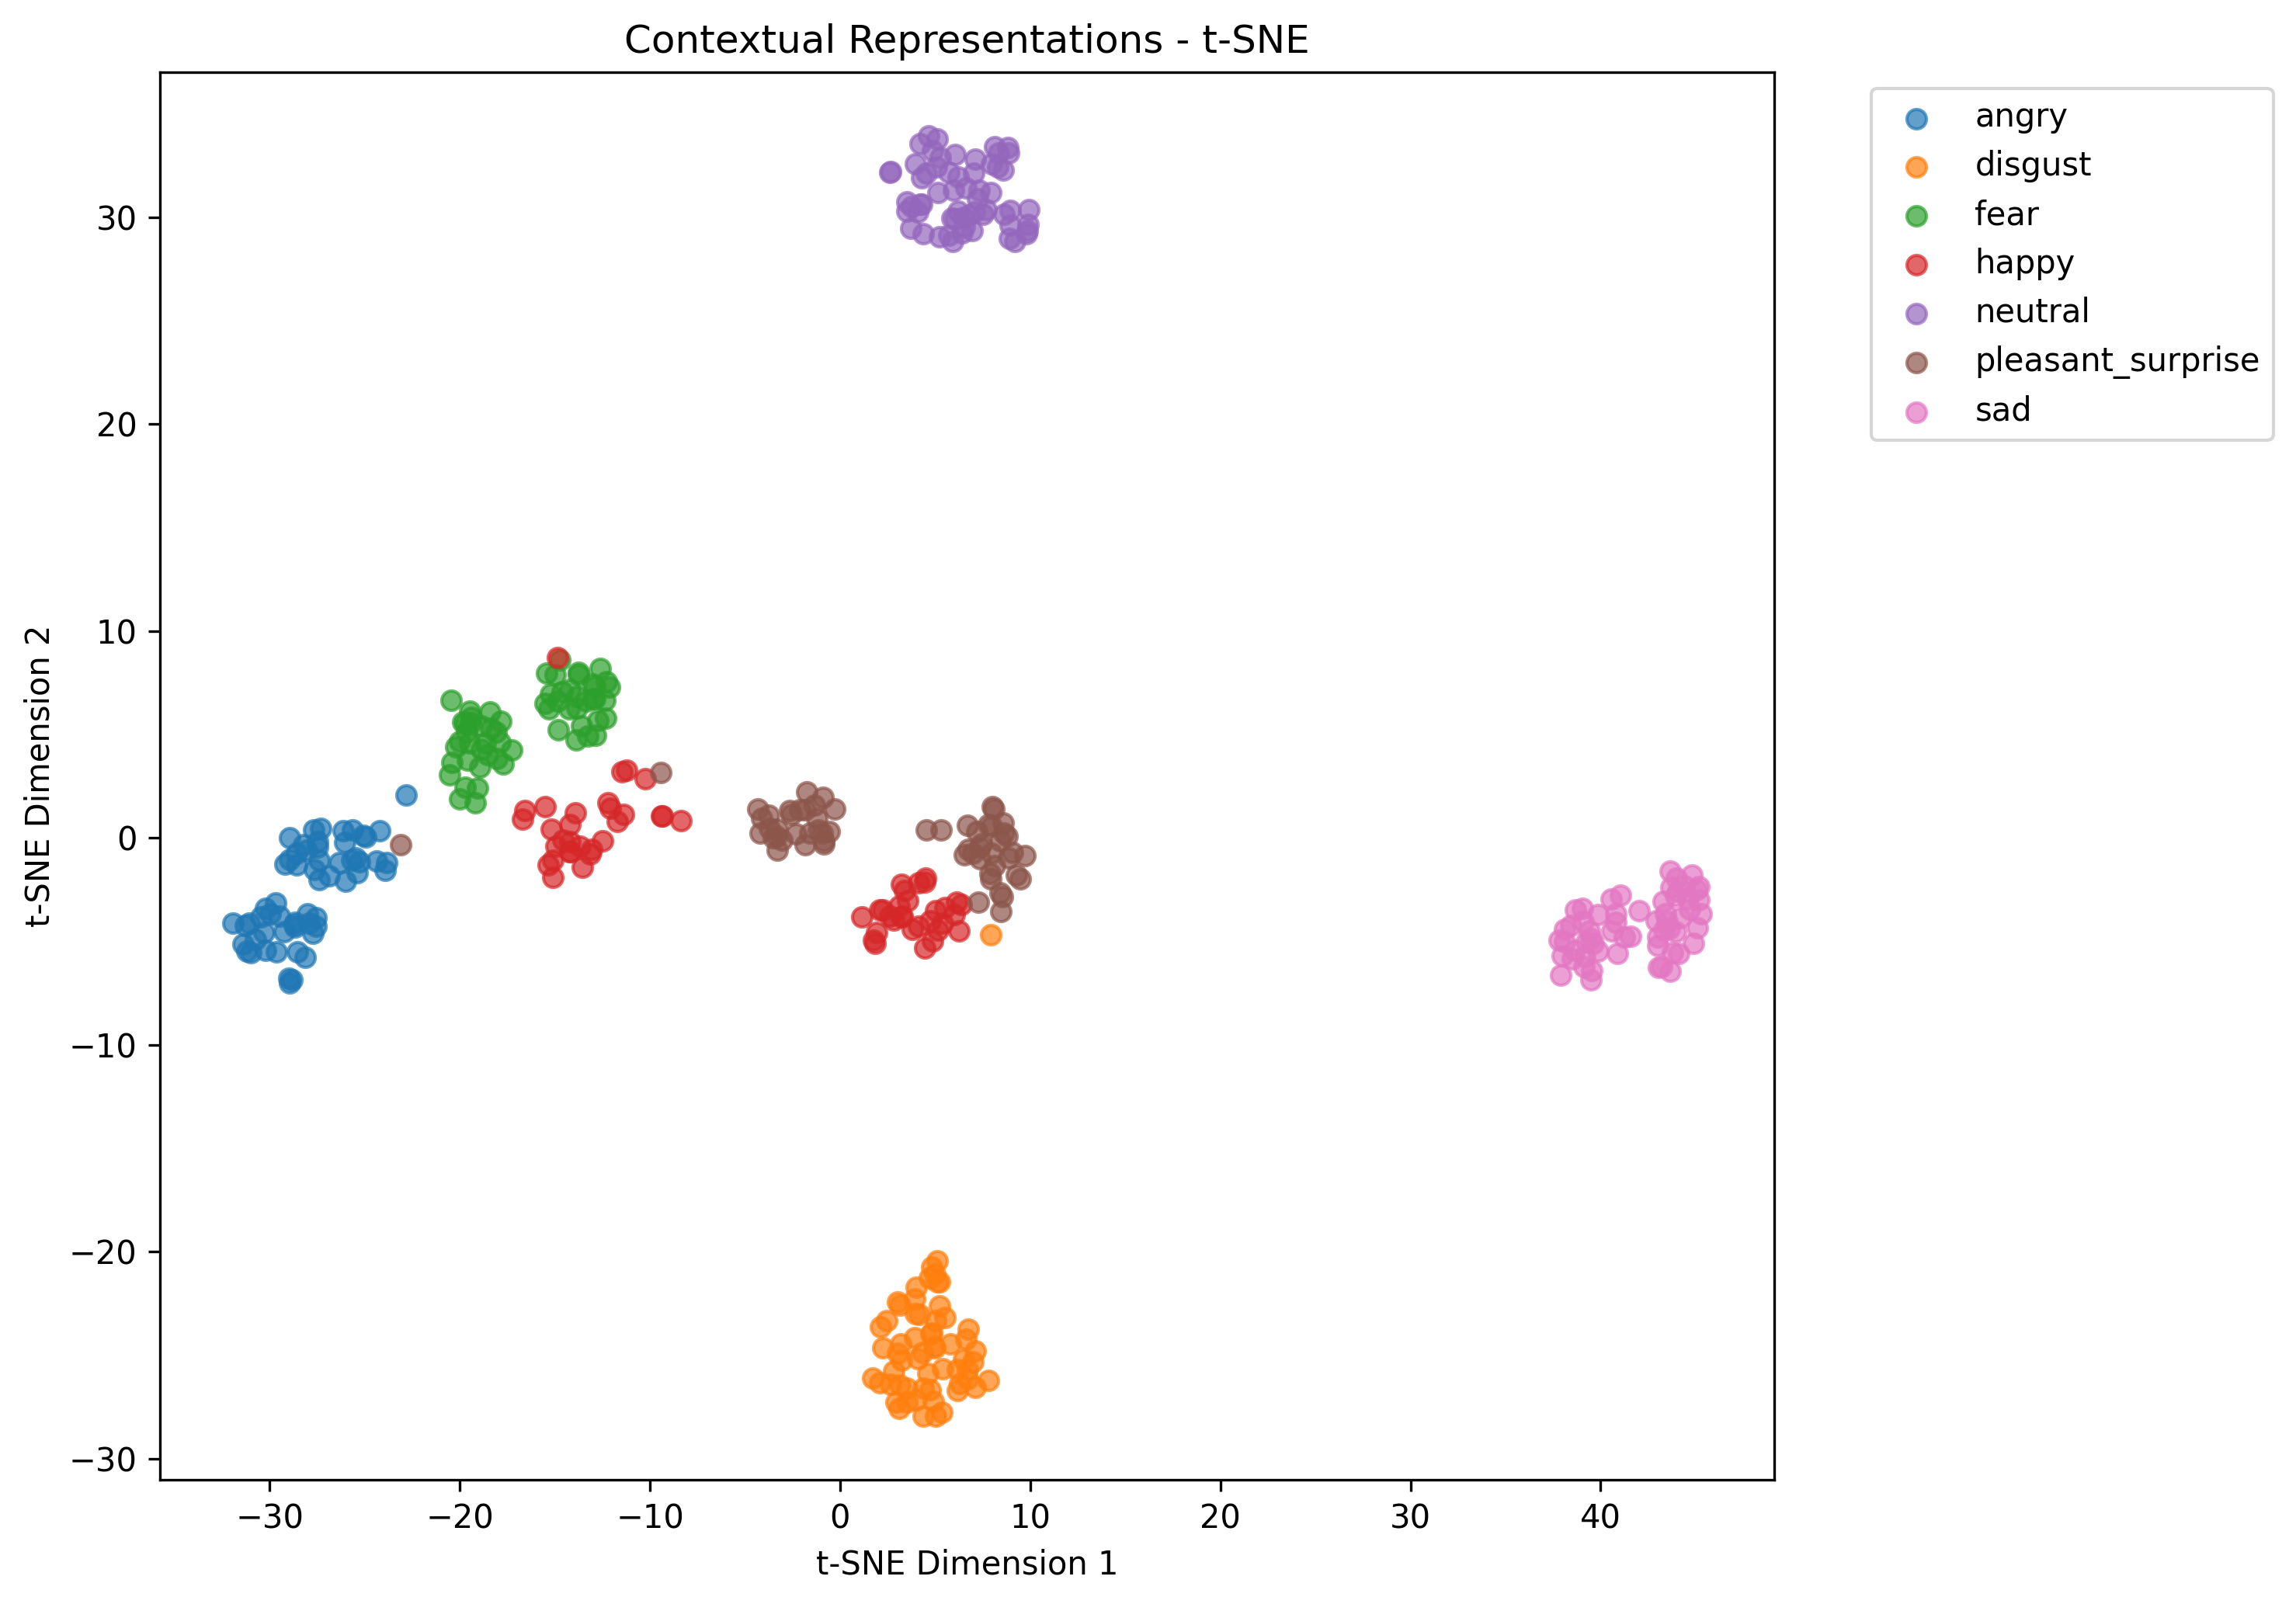

fusion_tsne.png


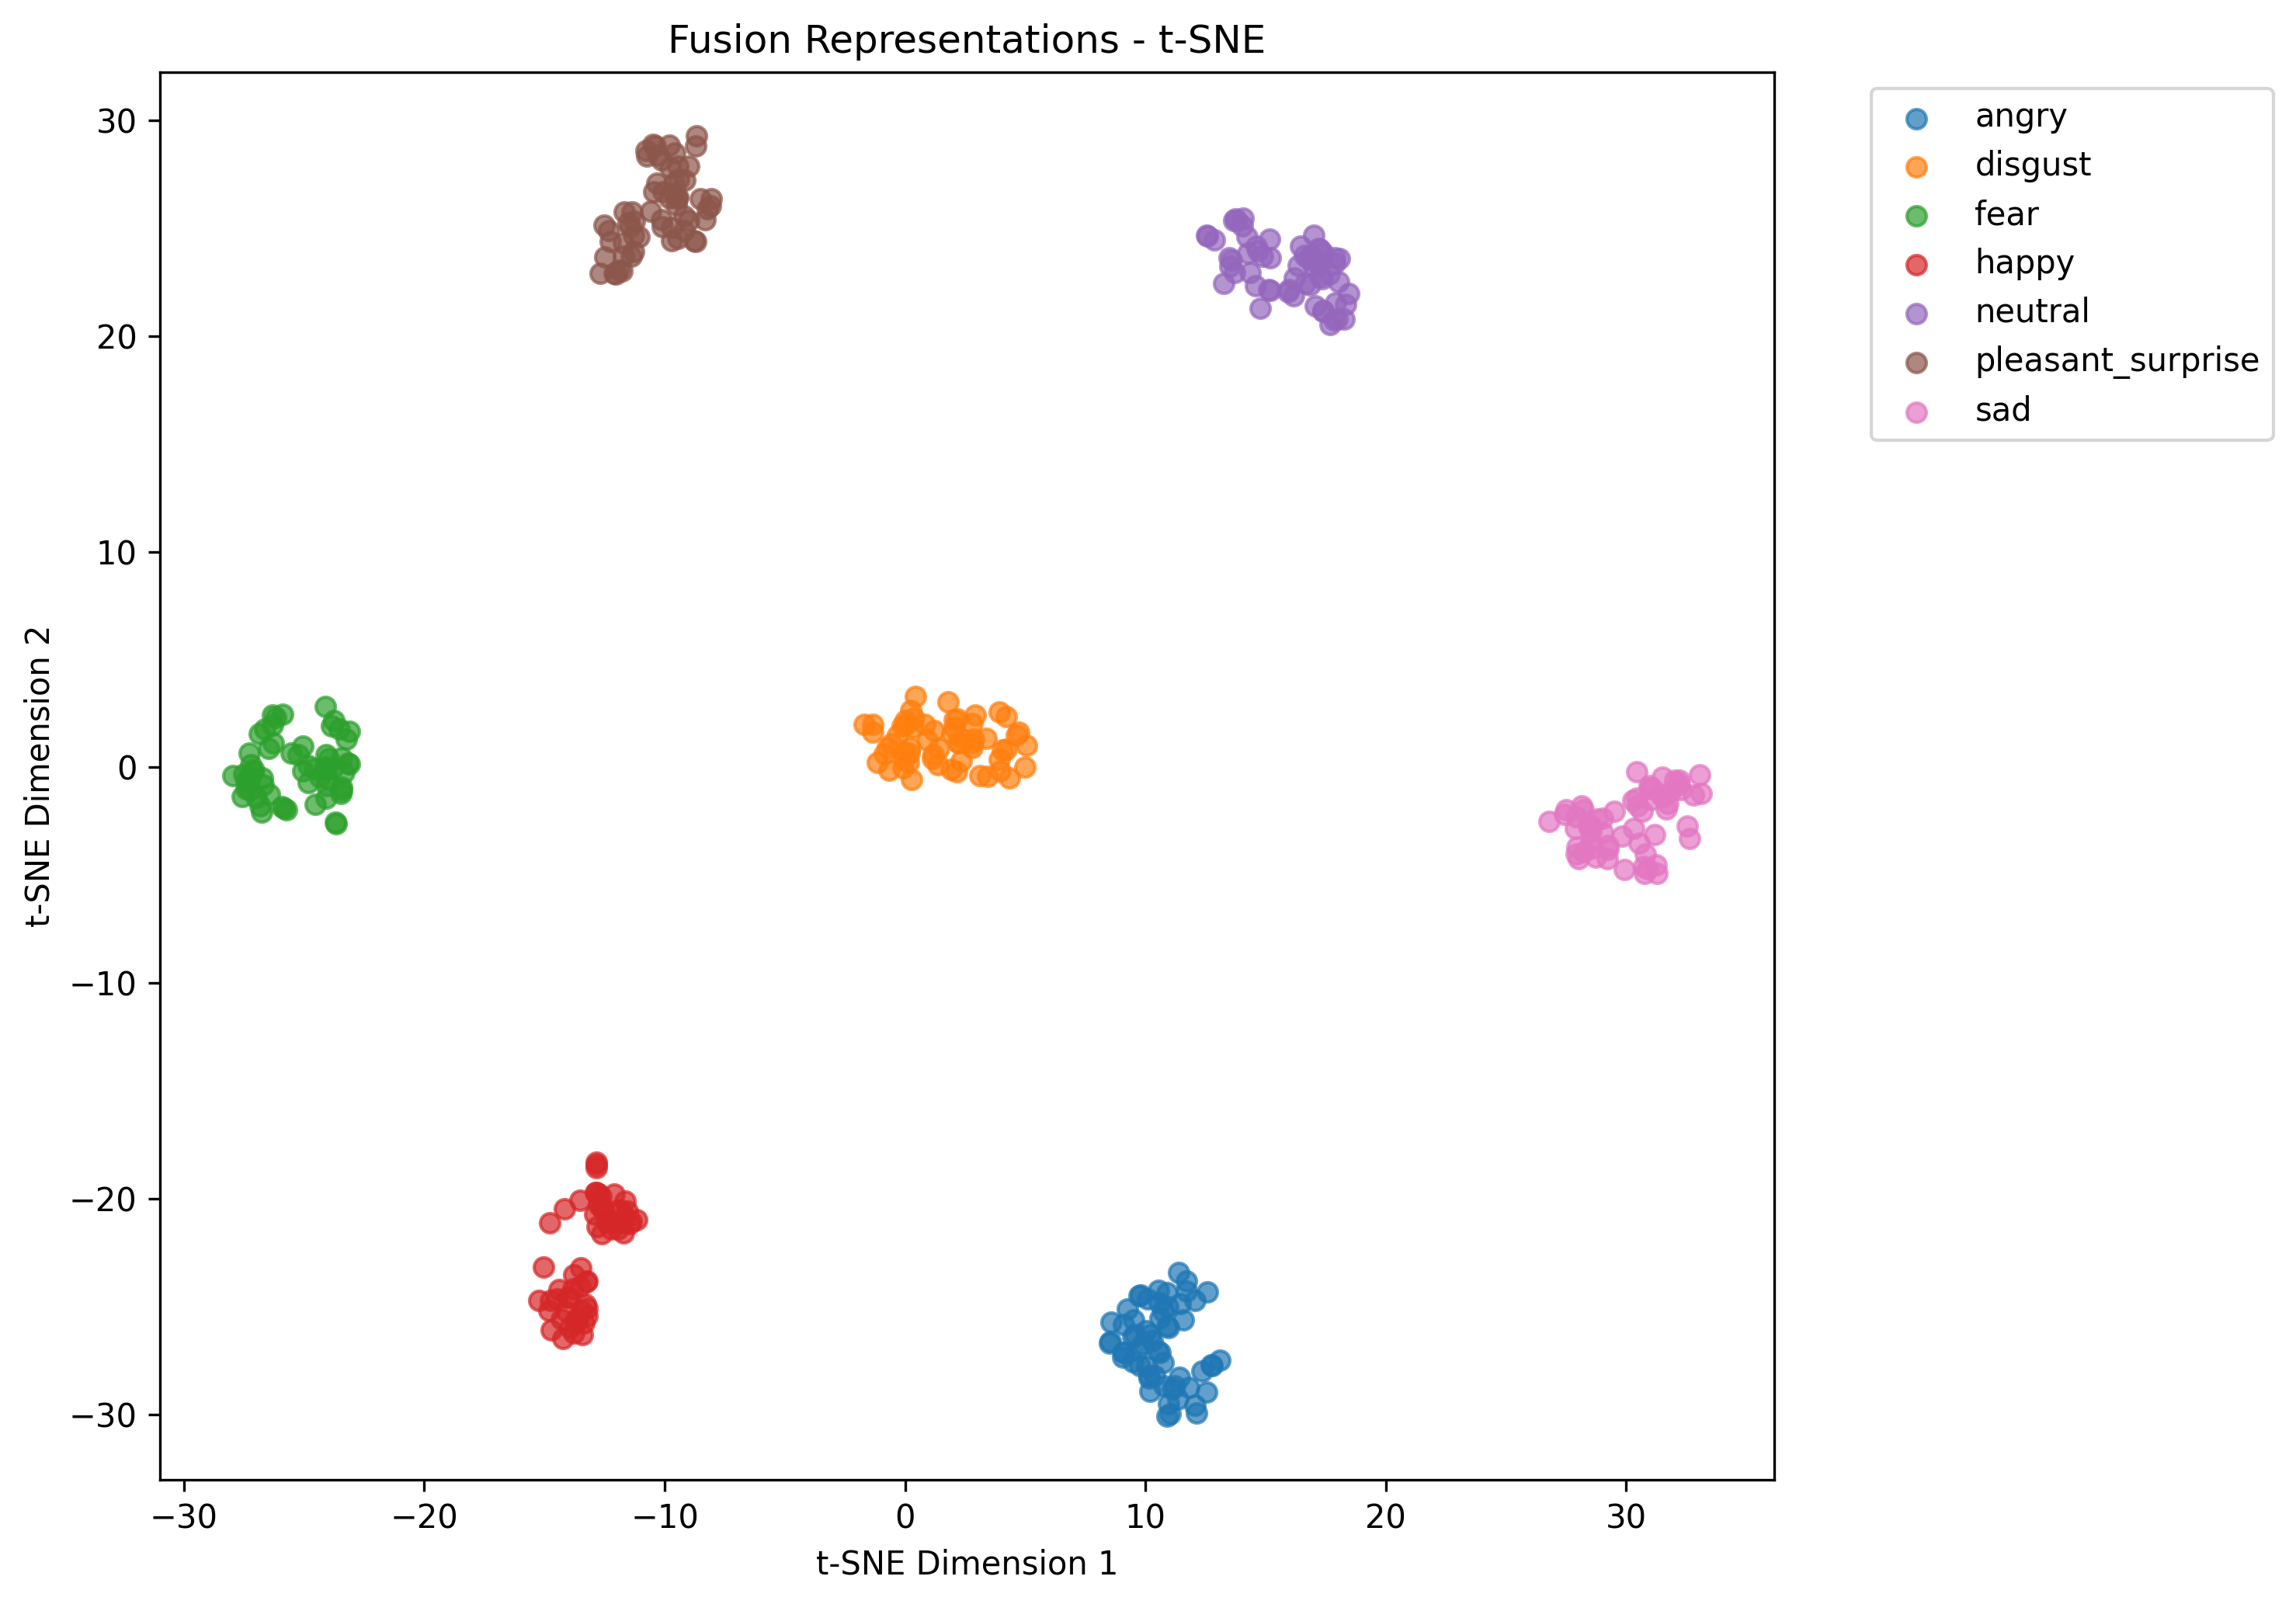

In [109]:
import os
from IPython.display import display, Image

plot_dir = os.path.join(DATA_DIR, "Results", "plots")

for filename in ["contextual_tsne.png", "fusion_tsne.png"]:
    path = os.path.join(plot_dir, filename)

    print(filename)
    if os.path.exists(path):
        display(Image(filename=path))
    else:
        print("File not found:", path)